# Baseline models: forecasting next month's orders, returns and sales

**Scope:** Online ES and Online PT. Data from 2024-01-01 to 2025-12-31. Orders dated before 2024 are excluded.

## 1. Preparing the daily data for Online ES and Online PT

**What we will do:** Connect to the bronze data layer for now (we will switch to gold later), select orders from both markets dated 2024 onwards, and build a daily table for each market (731 days) containing orders, units, Gross sales and returns.

**Why:** This gives us a common starting point for all baseline models and keeps the code for each model simpler.

**Definitions:**
- **Order:** An order with at least one sales line and more units sold than cancelled, based on the order date (`order_cab`).
- **Gross sales:** The discounted value, excluding VAT and in euros, of SALE and CANCELLED lines (cancellations are negative), based on the order date.
- **Returns:** RETURN lines based on the movement date (`order_det`), for orders from 2024 onwards. Units and value are shown as positive amounts.
- **Net sales:** Gross sales minus the value of returns (calculated when data is grouped by month).

**Reference figures (from the exploration notebook):**
- Online ES: 2,073,748 orders with a sale; 2,064,896 not fully cancelled.
- Online PT: 725,530 orders with a sale; 722,673 not fully cancelled.
- Return lines from January to June 2024 (ES + PT): 28,104, 25,614, 18,651, 20,347, 27,351 and 33,770.
- Orders with at least one return (ES + PT): 688,453.

**No previous reference figures available for:** Gross sales, units and return value.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake

# ---------- âmbito (decisão do grupo) ----------
MARKETS = ['Online ES', 'Online PT']      # para incluir o ECI ES, acrescentar 'ECI ES' (e actualizar os controlos)
START, END = '2024-01-01', '2025-12-31'   # encomendas anteriores a 2024 ficam eliminadas (decisão do grupo)

def fmt(n):
    # separador de milhares com ponto; int(round()) aceita inteiros e decimais
    return f"{int(round(n)):,}".replace(',', '.') if n is not None and not pd.isna(n) else '-'

def reset(con):
    # depois de um erro, a transação pode ficar abortada e bloquear as consultas seguintes
    try:
        con.execute('ROLLBACK')
    except Exception:
        pass

reset(con)
base = f"{lake.uri('bronze')}/mysql"

def files(table):
    return [r[0] for r in con.sql(f"SELECT file FROM glob('{base}/{table}/**/*.parquet') ORDER BY file").fetchall()]

lst_cab = ', '.join(f"'{f}'" for f in files('order_cab'))
lst_det = ', '.join(f"'{f}'" for f in files('order_det'))
if not lst_cab or not lst_det:
    raise RuntimeError("Não encontrei os ficheiros de order_cab/order_det na bronze. Confirma o lake.")
print('Ficheiros order_cab:', len(files('order_cab')), '| order_det:', len(files('order_det')), '(esperado 1 e 1)')

# ---------- pasta de provas do notebook baseline (separada da do notebook de exploração) ----------
EVID = Path('evidence_baseline'); EVID.mkdir(exist_ok=True)
LOG = EVID / 'evidence_log.csv'
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
                     'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})

def _log(eid, kind, title, scope, filename):
    row = pd.DataFrame([{'id': eid, 'kind': kind, 'title': title, 'scope': scope, 'file': filename}])
    if LOG.exists():
        old = pd.read_csv(LOG)
        row = pd.concat([old[old['id'] != eid], row], ignore_index=True)   # substitui se o ID já existe
    row.to_csv(LOG, index=False)

def save_table(df, eid, title, scope):
    df.to_csv(EVID / f'{eid}.csv', index=False); _log(eid, 'table', title, scope, f'{eid}.csv'); print('Guardado:', EVID / f'{eid}.csv')

def save_fig(fig, eid, title, scope):
    fig.savefig(EVID / f'{eid}.png', dpi=200, bbox_inches='tight'); _log(eid, 'figure', title, scope, f'{eid}.png'); print('Guardado:', EVID / f'{eid}.png')

mk_in = ', '.join(f"'{m}'" for m in MARKETS)
mk_values = ', '.join(f"('{m}')" for m in MARKETS)

# 1) Encomendas do âmbito. O cabeçalho repete-se por linha de produto, por isso agrupamos por ORDER_ID.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_orders AS
SELECT ORDER_ID, mark, order_ts FROM (
  SELECT ORDER_ID, min(MARK_COD) AS mark, min(try_cast(ORDER_DATE AS TIMESTAMP)) AS order_ts
  FROM read_parquet([{lst_cab}]) GROUP BY ORDER_ID)
WHERE mark IN ({mk_in}) AND CAST(order_ts AS DATE) BETWEEN DATE '{START}' AND DATE '{END}'
""")

# 2) Uma linha por encomenda: unidades e valor (com desconto, sem IVA, em euros). Cancelamentos têm sinal negativo.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_facts AS
SELECT s.ORDER_ID, s.mark, CAST(s.order_ts AS DATE) AS order_d,
       count(*) FILTER (WHERE d.TYPE = 'SALE') AS sale_lines,
       COALESCE(sum(d.PROD_QTY) FILTER (WHERE d.TYPE = 'SALE'), 0) AS sale_units,
       COALESCE(sum(d.PROD_QTY) FILTER (WHERE d.TYPE = 'CANCELLED'), 0) AS cancel_units,
       COALESCE(sum(d.AMOUNT_FIXED_RATE_W_DISC_WO_VAT) FILTER (WHERE d.TYPE IN ('SALE', 'CANCELLED')), 0) AS gross_value
FROM scope_orders s JOIN read_parquet([{lst_det}]) d ON d.ORDER_ID = s.ORDER_ID
GROUP BY s.ORDER_ID, s.mark, s.order_ts
""")

# 3) Devoluções por mercado e dia do movimento (só de encomendas do âmbito); unidades e valor em positivo
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_returns AS
SELECT s.mark, CAST(try_strptime(CAST(d.MOV_DATE_SFK AS VARCHAR), '%Y%m%d') AS DATE) AS ret_d,
       count(*) AS return_lines, -sum(d.PROD_QTY) AS return_units, -sum(d.AMOUNT_FIXED_RATE_W_DISC_WO_VAT) AS return_value
FROM read_parquet([{lst_det}]) d JOIN scope_orders s ON d.ORDER_ID = s.ORDER_ID
WHERE d.TYPE = 'RETURN' GROUP BY 1, 2
""")

# 4) Tabela diária por mercado (731 dias), com 0 nos dias sem registos
con.execute(f"""
CREATE OR REPLACE TEMP TABLE daily_mk AS
WITH days AS (SELECT CAST(t AS DATE) AS day
              FROM generate_series(TIMESTAMP '{START}', TIMESTAMP '{END}', INTERVAL 1 DAY) AS g(t)),
mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
o AS (
  SELECT mark, order_d AS day,
         count(*) FILTER (WHERE sale_lines > 0) AS orders_with_sale,
         count(*) FILTER (WHERE sale_lines > 0 AND round(sale_units + cancel_units) > 0) AS orders,
         COALESCE(sum(sale_units + cancel_units) FILTER (WHERE sale_lines > 0), 0) AS net_units,
         COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0), 0) AS gross_sales
  FROM scope_facts GROUP BY 1, 2)
SELECT mk.mark, days.day,
       COALESCE(o.orders_with_sale, 0) AS orders_with_sale, COALESCE(o.orders, 0) AS orders,
       COALESCE(o.net_units, 0) AS net_units, COALESCE(o.gross_sales, 0) AS gross_sales,
       COALESCE(r.return_lines, 0) AS return_lines, COALESCE(r.return_units, 0) AS return_units,
       COALESCE(r.return_value, 0) AS return_value
FROM days CROSS JOIN mk
LEFT JOIN o ON o.mark = mk.mark AND o.day = days.day
LEFT JOIN scope_returns r ON r.mark = mk.mark AND r.ret_d = days.day
ORDER BY mk.mark, days.day
""")

# ---------- controlos contra o que já medimos no notebook de exploração ----------
chk = con.sql("""SELECT mark, count(*) AS dias, sum(orders_with_sale) AS com_venda, sum(orders) AS encomendas,
                        sum(net_units) AS unidades, sum(gross_sales) AS gross_sales,
                        sum(return_lines) AS linhas_devolucao, sum(return_units) AS unidades_devolvidas,
                        sum(return_value) AS valor_devolvido
                 FROM daily_mk GROUP BY 1 ORDER BY 1""").df().set_index('mark')
exp = {'Online ES': (2_073_748, 2_064_896), 'Online PT': (725_530, 722_673)}   # (com venda, não totalmente canceladas)
chk['bate_com_venda'] = [chk.loc[m, 'com_venda'] == exp[m][0] if m in exp else None for m in chk.index]
chk['bate_encomendas'] = [chk.loc[m, 'encomendas'] == exp[m][1] if m in exp else None for m in chk.index]
show = chk.copy()
for c in ['dias', 'com_venda', 'encomendas', 'unidades', 'gross_sales', 'linhas_devolucao', 'unidades_devolvidas', 'valor_devolvido']:
    show[c] = show[c].map(fmt)
print('--- Controlo por mercado (dias esperados: 731; valores em euros, sem IVA, com desconto) ---')
display(show)

if MARKETS == ['Online ES', 'Online PT']:
    exp_ret = {'2024-01': 28104, '2024-02': 25614, '2024-03': 18651, '2024-04': 20347, '2024-05': 27351, '2024-06': 33770}
    r = con.sql("""SELECT strftime(day, '%Y-%m') AS mes, sum(return_lines) AS linhas FROM daily_mk
                   WHERE day < DATE '2024-07-01' GROUP BY 1 ORDER BY 1""").df()
    r['esperado'] = r['mes'].map(exp_ret); r['bate'] = r['linhas'] == r['esperado']
    print('\n--- Controlo: linhas de devolução de jan a jun de 2024 (ES + PT; célula 27c) ---')
    display(r)
    n_ret = con.execute(f"""SELECT count(DISTINCT s.ORDER_ID) FROM scope_orders s
                        JOIN read_parquet([{lst_det}]) d ON d.ORDER_ID = s.ORDER_ID WHERE d.TYPE = 'RETURN'""").fetchall()[0][0]
    print('Encomendas com devolução:', fmt(n_ret), '(esperado 688.453; célula 27d)')

# primeiras e últimas linhas da tabela diária, para ver a estrutura
print('\n--- Estrutura da tabela diária (Online ES: 3 primeiros e 3 últimos dias) ---')
dm = con.sql("SELECT * FROM daily_mk WHERE mark = 'Online ES' ORDER BY day").df()
display(pd.concat([dm.head(3), dm.tail(3)]))

# Cópia local para reutilizar nas células seguintes sem voltar a ler o lake
con.execute("COPY daily_mk TO 'daily_es_pt.parquet' (FORMAT PARQUET)")   # o DuckDB escreve o Parquet, sem dependências extra
print('\nGuardado: daily_es_pt.parquet (tabela diária, uma linha por mercado e dia)')

# Eficiência: tempo O(n) por passagem sobre order_cab e order_det (9 milhões de linhas cada), com 3 junções hash
# a scope_orders; espaço O(d), com d ≈ 2,8 milhões de encomendas de ES e PT. A tabela diária tem 731 × nº de mercados linhas.

Ficheiros order_cab: 1 | order_det: 1 (esperado 1 e 1)
--- Controlo por mercado (dias esperados: 731; valores em euros, sem IVA, com desconto) ---


,dias,com_venda,encomendas,unidades,gross_sales,linhas_devolucao,unidades_devolvidas,valor_devolvido,bate_com_venda,bate_encomendas
mark,,,,,,,,,,
Online ES,731,2.073.748,2.064.896,3.936.852,42.565.898,882.523,882.523,10.822.559,True,True
Online PT,731,725.530,722.673,1.374.012,13.462.680,208.928,208.928,2.420.692,True,True



--- Controlo: linhas de devolução de jan a jun de 2024 (ES + PT; célula 27c) ---


,mes,linhas,esperado,bate
0,2024-01,28104.0,28104,True
1,2024-02,25614.0,25614,True
2,2024-03,18651.0,18651,True
3,2024-04,20347.0,20347,True
4,2024-05,27351.0,27351,True
5,2024-06,33770.0,33770,True


Encomendas com devolução: 688.453 (esperado 688.453; célula 27d)

--- Estrutura da tabela diária (Online ES: 3 primeiros e 3 últimos dias) ---


,mark,day,orders_with_sale,orders,net_units,gross_sales,return_lines,return_units,return_value
0,Online ES,2024-01-01,1789,1789,2880.0,33630.14922,0,0.0,0.00000
1,Online ES,2024-01-02,3512,3505,5507.0,64157.00562,0,0.0,0.00000
2,Online ES,2024-01-03,1272,1270,1924.0,22743.57978,6,6.0,95.17692
728,Online ES,2025-12-29,6368,6349,9220.0,131837.03844,2786,2786.0,35985.16494
729,Online ES,2025-12-30,5444,5438,8047.0,113470.24500,2534,2534.0,34418.31060
730,Online ES,2025-12-31,1791,1789,2551.0,36033.77490,759,759.0,10546.28832



Guardado: daily_es_pt.parquet (tabela diária, uma linha por mercado e dia)


### 1a. Findings

**Confirmed (full table):**
- All checks match.
- The daily table contains 731 days per market (2024-01-01 to 2025-12-31).
- Across both markets, there are 2,787,569 orders, Gross sales of €56,028,578, recorded returns worth €13,243,251 and Net sales of €42,785,327 (discounted values, excluding VAT).
- Average value per order (Gross sales divided by orders) is €20.61 in Spain and €18.63 in Portugal. Units per order are similar (1.91 and 1.90).
- In both markets, each return line represents one unit (return lines = returned units: 882,523 in ES and 208,928 in PT).
- Portugal has a lower return rate than Spain. Returned units divided by sold units are 15.2% versus 22.4%, and returned value divided by Gross sales is 18.0% versus 25.4%. Portugal accounts for 25.9% of orders and 24.0% of Gross sales.
- The value per returned unit (€12.26 in ES and €11.59 in PT) is higher than Gross sales per sold unit (€10.81 and €9.80).

**Still to be checked:**
- Return rates are approximate: they compare returns recorded in 2024 and 2025 with sales from the same period, without matching returns to the original sales period. Returns for sales made in December 2025 are not yet included in the data.
- Why is the value per returned unit higher than the value per sold unit? Possible explanations include more expensive items, discounts not being reflected, or the quantity not actually representing one unit.

## 2. Test setup: cut-off date, training period, test period and metrics

**What we will do:**
a) Build a monthly table of actual figures for each market.
b) Set the rules: the cut-off is the last day of M-2; the 12 target months are January to December 2025; January to July is the training period and August to December is the test period.
c) Define the metrics: WAPE (shows the overall size of the forecasting error), bias (shows whether we tend to over- or under-forecast; in our case, a negative bias is preferable to a positive one), RMSE (shows the typical error in number of orders and gives more weight to large errors) and R² (shows how much of the month-to-month variation is explained by the forecast; it can be negative when the forecast is worse than simply using the average).
d) Create the functions used by the baseline models (`history`, `run` and `scorecard`) and test them with sample forecasts.

**Why:** Make sure that no baseline model can use future information and that every model is assessed in the same way.

**Rules:**
- To forecast month M, we can only use data up to the last day of M-2.
- Training period (used to choose the model): January to July 2025. Test period (used only for reporting): August to December 2025.
- All comparisons use monthly totals, by market and for ES + PT combined.
- Forecast detail: monthly for B1, B2, B3 and B5; weekly for B5; daily for B1, B2, B3, B4 and B5 (10 runs).

**Reference figures (M1 from the exploration notebook):** monthly orders for Online ES and Online PT in January 2024 (80,536 and 33,096), November 2025 (167,029 and 58,003) and December 2025 (129,546 and 35,111); total ES + PT in 2024 (1,222,452) and 2025 (1,565,117).

**Why WAPE is a good choice:**
- It takes sales volume into account. An error of 1,000 orders in a month with 100,000 orders has a different impact from an error of 1,000 in a month with 10,000 orders.
- It is easy to understand. A WAPE of 10% means that the total absolute forecasting error is equal to 10% of the actual total volume.
- It allows us to compare models and levels of detail (monthly, weekly or daily).
- Importantly, WAPE naturally gives more weight to months with a higher number of orders.

**Bias shows the direction of the error:**
- Positive bias: the forecast is too high (we predict more than actually happens).
- Negative bias: the forecast is too low (we predict less than actually happens).

**RMSE shows the typical error in number of orders:**
- It is the square root of the average squared errors, so it is expressed in the same unit as the target. An RMSE of 20,000 means that the typical error is around 20,000 orders per month.
- It gives more weight to large errors: one month with a very poor forecast can matter more than several months with small errors.
- It is not a percentage, so it should only be used to compare models within the same market and period (Spain and Portugal have different scales).

**R² shows how much of the actual variation is explained by the forecast:**
- R² = 1 − (sum of squared errors ÷ sum of squared differences between actual values and their average). It is 1 when the forecast is perfect, 0 when it is no better than always forecasting the average of the actual months, and negative when it performs worse.
- It can be unstable when there are only a few months. Training has 7 months and testing has 5, but the comparison with B3 has only 3 training months (May, June and July), because B3 needs a full year of historical data and is only available from May onwards. One poorly forecast month can change the result significantly. For this reason, R² should be interpreted carefully and should never be the only reason for choosing a model.
- It is not calculated for a single month (shown as “-”), or by combining Spain and Portugal into one sample, because the different market sizes would distort the result. It is calculated separately for each market and for ES + PT combined.

We calculate the metrics across the full set of months, rather than taking the average of the monthly percentages. This matters when assessing the overall impact of forecasts on order volume and choosing a baseline. For the baseline models, WAPE is the main decision metric: for example, it is used to choose the window length for B5. Bias, RMSE and R² are also shown in the tables to help us understand the results from other angles: the direction of the error, the size of large errors and how much of the variation is explained.

In [2]:
import pandas as pd
import numpy as np

# Uses fmt()/reset()/save_table() e MARKETS (célula 1) e a tabela daily_mk (célula 1).
# If you restarted the kernel, run a célula 1.
reset(con)
try:
    daily = con.sql("SELECT * FROM daily_mk").df()
except Exception:
    daily = con.sql("SELECT * FROM 'daily_es_pt.parquet'").df()     # cópia local guardada na célula 1
daily['day'] = pd.to_datetime(daily['day'])
daily['month'] = daily['day'].dt.to_period('M')

# ---------- tabela mensal por mercado (valores reais) ----------
VALUE_COLS = ['orders_with_sale', 'orders', 'net_units', 'gross_sales', 'return_lines', 'return_units', 'return_value']
monthly = daily.groupby(['mark', 'month'])[VALUE_COLS].sum().reset_index()
monthly['net_sales'] = monthly['gross_sales'] - monthly['return_value']     # Net = Gross - devoluções registadas no mês

# Controlos: as encomendas mensais têm de coincidir com a tabela M1 do notebook de exploração
ref = {('Online ES', '2024-01'): 80536, ('Online PT', '2024-01'): 33096,
       ('Online ES', '2025-11'): 167029, ('Online PT', '2025-11'): 58003,
       ('Online ES', '2025-12'): 129546, ('Online PT', '2025-12'): 35111}
ck = pd.DataFrame([{'mercado': k[0], 'mês': k[1],
                    'medido': int(monthly[(monthly['mark'] == k[0]) & (monthly['month'] == pd.Period(k[1], 'M'))]['orders'].iloc[0]),
                    'esperado': v} for k, v in ref.items()])
ck['bate'] = ck['medido'] == ck['esperado']
print('--- Controlo: encomendas mensais (M1 do notebook de exploração) ---')
display(ck)
tot_year = monthly.groupby(monthly['month'].dt.year)['orders'].sum()
print('Encomendas ES + PT por ano:', {int(y): fmt(v) for y, v in tot_year.items()},
      '(esperado 2024: 1.222.452 | 2025: 1.565.117)')

# ---------- regras do teste (decisões do grupo) ----------
FIRST = pd.Period('2024-01', 'M')
TARGETS = [pd.Period(f'2025-{i:02d}', 'M') for i in range(1, 13)]      # 12 meses-alvo; os primeiros têm pouco histórico

def cutoff_date(m):
    # Cut-off: last day of month M-2. For example, a September forecast uses data up to 31 July.
    return (pd.Period(m, 'M') - 2).end_time.normalize()

def months_of_history(m):
    # Number of complete months available, from January 2024 to M-2
    return ((pd.Period(m, 'M') - 2) - FIRST).n + 1

def split_of(m):
    # Training period (Jan-Jul 2025) used for selection; test period (Aug-Dec 2025) used for reporting only
    return 'Training' if pd.Period(m, 'M') <= pd.Period('2025-07', 'M') else 'Test'

def history(df, m):
    # Returns only days up to the target month's cut-off; it never returns future data
    h = df[df['day'] <= cutoff_date(m)]
    assert h['day'].max() <= cutoff_date(m), 'fuga de informação: dados depois do corte'
    return h

MONTH_NAMES = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
rules = pd.DataFrame({
    'Month to forecast': [f'{MONTH_NAMES[m.month - 1]} {m.year}' for m in TARGETS],
    'Data used up to': [cutoff_date(m).strftime('%Y-%m-%d') for m in TARGETS],
    'Months of history': [months_of_history(m) for m in TARGETS],
    'Period': [split_of(m) for m in TARGETS],
})
print('\n--- Regras do teste: corte, histórico e período de cada mês-alvo ---')
display(rules)
save_table(rules, 'BL1', 'Test rules: month to forecast, last day of data allowed, months of history and period', 'whole table')

# Prova de que a função "history" corta bem: para setembro de 2025 o último dia visível tem de ser 31 de julho
h = history(daily, pd.Period('2025-09', 'M'))
print('\nÚltimo dia visível ao prever setembro de 2025:', h['day'].max().date(), '(esperado 2025-07-31)')

# ---------- métricas ----------
def wape(actual, forecast):
    # soma dos erros absolutos a dividir pela soma dos valores reais
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return np.abs(f - a).sum() / a.sum()

def bias(actual, forecast):
    # positivo = prevê acima do real; negativo = prevê abaixo
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return (f - a).sum() / a.sum()

def rmse(actual, forecast):
    # Root mean squared error, in the target's unit (orders); gives more weight to large errors
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return float(np.sqrt(np.mean((f - a) ** 2)))

def r2(actual, forecast):
    # 1 - SSE/SST, with SST measured around the actual average for the evaluated group. Can be negative (worse than forecasting the average).
    # Not defined with fewer than 2 months or when actual values do not vary.
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    sst = ((a - a.mean()) ** 2).sum()
    return np.nan if len(a) < 2 or sst == 0 else float(1 - ((a - f) ** 2).sum() / sst)

# Testes às métricas com um exemplo à mão: real 100 e 200, previsto 110 e 180 -> erros absolutos 10 + 20 = 30 sobre 300
assert abs(wape([100, 200], [110, 180]) - 30 / 300) < 1e-12
assert abs(bias([100, 200], [110, 180]) - (-10 / 300)) < 1e-12
# RMSE = raiz((100 + 400)/2); R² = 1 - 500/5000 (SST = 50² + 50² = 5000)
assert abs(rmse([100, 200], [110, 180]) - np.sqrt(250)) < 1e-12
assert abs(r2([100, 200], [110, 180]) - 0.9) < 1e-12
assert np.isnan(r2([100], [90]))
print('Métricas testadas: WAPE =', f"{100 * wape([100, 200], [110, 180]):.1f}%".replace('.', ','),
      '| viés =', f"{100 * bias([100, 200], [110, 180]):.1f}%".replace('.', ','),
      '| RMSE =', f"{rmse([100, 200], [110, 180]):.2f}".replace('.', ','),
      '| R² =', f"{r2([100, 200], [110, 180]):.2f}".replace('.', ','))

# ---------- ferramentas para as células seguintes ----------
def run(method_name, func, target='orders', markets=None):
    # func(h_mercado, mês_alvo, coluna_alvo) devolve a previsão mensal ou None se o método não existe nesse mês.
    # O método só recebe os dados até ao corte (history), por isso não pode ver o futuro.
    rows = []
    for m in TARGETS:
        h = history(daily, m)
        for mk in (markets or MARKETS):
            f = func(h[h['mark'] == mk], m, target)
            if f is not None:
                rows.append({'method': method_name, 'mark': mk, 'month': m, 'forecast': float(f)})
    return pd.DataFrame(rows)

def scorecard(fc, target='orders'):
    # junta o valor real, soma os dois mercados (ES + PT) e calcula WAPE, viés, RMSE e R² por método, mercado e período
    act = monthly.set_index(['mark', 'month'])[target].rename('actual')
    d = fc.join(act, on=['mark', 'month'])
    tot = d.groupby(['method', 'month'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')      # o total só conta meses em que há previsão dos dois mercados
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['month'].map(split_of)
    d['abs_err'] = (d['forecast'] - d['actual']).abs(); d['err'] = d['forecast'] - d['actual']; d['sq_err'] = d['err'] ** 2
    keys = ['method', 'mark', 'split']
    g = d.groupby(keys, as_index=False).agg(
        abs_err=('abs_err', 'sum'), err=('err', 'sum'), sq_err=('sq_err', 'sum'), actual=('actual', 'sum'), months=('month', 'count'))
    g['WAPE'] = g['abs_err'] / g['actual']; g['Bias'] = g['err'] / g['actual']
    g['RMSE'] = np.sqrt(g['sq_err'] / g['months'])                       # raiz da média dos erros quadrados mensais
    # R²: SST = soma dos quadrados dos desvios do real em torno da média do grupo; não definido com 1 mês ou sem variação
    sst = d.groupby(keys)['actual'].agg(lambda a: ((a - a.mean()) ** 2).sum()).rename('sst').reset_index()
    g = g.merge(sst, on=keys)
    g['R2'] = (1 - g['sq_err'] / g['sst']).where((g['months'] >= 2) & (g['sst'] > 0))
    return g[['method', 'mark', 'split', 'months', 'WAPE', 'Bias', 'RMSE', 'R2']]

# Teste das ferramentas com previsões de brincadeira: valor real (erro 0%) e valor real + 10% (erro e viés de 10%)
fc_ok = monthly[monthly['month'].isin(TARGETS)][['mark', 'month', 'orders']].rename(columns={'orders': 'forecast'})
fc_ok['method'] = 'test: real value'
fc_up = fc_ok.copy(); fc_up['forecast'] *= 1.10; fc_up['method'] = 'test: real value + 10%'
sc = scorecard(pd.concat([fc_ok, fc_up], ignore_index=True))

# o scorecard tem de dar o mesmo que as funções rmse() e r2() (ES, Training, real + 10%)
tr_m = [m for m in TARGETS if split_of(m) == 'Training']
a_es = monthly[(monthly['mark'] == 'Online ES') & monthly['month'].isin(tr_m)].sort_values('month')['orders'].to_numpy(float)
row = sc[(sc['method'] == 'test: real value + 10%') & (sc['mark'] == 'Online ES') & (sc['split'] == 'Training')].iloc[0]
assert abs(row['RMSE'] - rmse(a_es, 1.10 * a_es)) < 1e-6 and abs(row['R2'] - r2(a_es, 1.10 * a_es)) < 1e-9
print('Scorecard coerente com rmse() e r2(): True')

sc['WAPE'] = (100 * sc['WAPE']).round(1).astype(str) + '%'; sc['Bias'] = (100 * sc['Bias']).round(1).astype(str) + '%'
sc['RMSE'] = sc['RMSE'].map(fmt); sc['R2'] = sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))
print('\n--- Teste das ferramentas (real: WAPE 0,0% e R² 1,00; real + 10%: WAPE e viés 10,0%) ---')
display(sc)

# Teste da função run com um método de brincadeira (constante 1): confirma o ciclo mercado x mês-alvo e o corte
t = run('test: constant', lambda h, m, tgt: 1.0)
print('Previsões geradas pelo método de teste:', len(t), '(esperado 12 meses x 2 mercados = 24)')

# Eficiência: agregações O(d·m) sobre a tabela diária (731 dias × nº de mercados, ~1.500 linhas); cada previsão filtra a tabela
# uma vez, O(d), por mês-alvo e mercado (24 vezes); espaço O(d·m).

--- Controlo: encomendas mensais (M1 do notebook de exploração) ---


,mercado,mês,medido,esperado,bate
0,Online ES,2024-01,80536,80536,True
1,Online PT,2024-01,33096,33096,True
2,Online ES,2025-11,167029,167029,True
3,Online PT,2025-11,58003,58003,True
4,Online ES,2025-12,129546,129546,True
5,Online PT,2025-12,35111,35111,True


Encomendas ES + PT por ano: {2024: '1.222.452', 2025: '1.565.117'} (esperado 2024: 1.222.452 | 2025: 1.565.117)

--- Regras do teste: corte, histórico e período de cada mês-alvo ---


,Month to forecast,Data used up to,Months of history,Period
0,January 2025,2024-11-30,11,Training
1,February 2025,2024-12-31,12,Training
2,March 2025,2025-01-31,13,Training
3,April 2025,2025-02-28,14,Training
4,May 2025,2025-03-31,15,Training
5,June 2025,2025-04-30,16,Training
6,July 2025,2025-05-31,17,Training
7,August 2025,2025-06-30,18,Test
8,September 2025,2025-07-31,19,Test
9,October 2025,2025-08-31,20,Test


Guardado: evidence_baseline/BL1.csv

Último dia visível ao prever setembro de 2025: 2025-07-31 (esperado 2025-07-31)
Métricas testadas: WAPE = 10,0% | viés = -3,3% | RMSE = 15,81 | R² = 0,90
Scorecard coerente com rmse() e r2(): True

--- Teste das ferramentas (real: WAPE 0,0% e R² 1,00; real + 10%: WAPE e viés 10,0%) ---


,method,mark,split,months,WAPE,Bias,RMSE,R2
0,test: real value,ES + PT,Test,5,0.0%,0.0%,0,"1,00"
1,test: real value,ES + PT,Training,7,0.0%,0.0%,0,"1,00"
2,test: real value,Online ES,Test,5,0.0%,0.0%,0,"1,00"
3,test: real value,Online ES,Training,7,0.0%,0.0%,0,"1,00"
4,test: real value,Online PT,Test,5,0.0%,0.0%,0,"1,00"
5,test: real value,Online PT,Training,7,0.0%,0.0%,0,"1,00"
6,test: real value + 10%,ES + PT,Test,5,10.0%,10.0%,14.611,"0,92"
7,test: real value + 10%,ES + PT,Training,7,10.0%,10.0%,13.134,"0,88"
8,test: real value + 10%,Online ES,Test,5,10.0%,10.0%,11.028,"0,92"
9,test: real value + 10%,Online ES,Training,7,10.0%,10.0%,9.698,"0,86"


Previsões geradas pelo método de teste: 24 (esperado 12 meses x 2 mercados = 24)


### 2a. Findings

**Confirmed (full table):**
- All checks match.
- The cut-off function works correctly: when forecasting September 2025, the latest available date is 2025-07-31.
- The rules are set as shown in the BL1 table: 12 target months; training from January to July 2025 (7 months) and testing from August to December (5 months). Available history ranges from 11 months (January 2025, cut-off on 2024-11-30) to 22 months (December 2025, cut-off on 2025-10-31).
- The metrics return the expected results in the sample test (WAPE 10.0%, bias −3.3%, RMSE 15.81 and R² 0.90). The scorecard, which groups results by market, training or test period and method, returns 0.0% WAPE and R² of 1.00 when actual values are used. When the forecast is 10% above the actual value, it returns 10.0% WAPE and bias for each market, for ES + PT and for each period. The scorecard's RMSE and R² match the results from the `rmse` and `r2` functions.
- The `run` function generates 24 forecasts (12 months × 2 markets) using the test method.

## 3. Baseline 1: average of all complete months available before the cut-off

**What we will do:** For each target month in 2025, forecast the value using the average of all complete months available before the cut-off (the last day of M-2). We will test two levels of detail: monthly (average of monthly totals) and daily (average per day multiplied by the number of days in the target month). We will measure the error by market, for ES + PT combined and by period (training and test), and compare the forecasts with the actual figures.

**Why:** Establish the simplest possible reference point, with no seasonality, campaign effects or trend, and see where it falls short.

**Forecast target for this run:** orders (`TARGET = 'orders'`).

**Reference figures (manual/Excel calculation, ES + PT, orders):** September 2025: monthly 110,732.5 and daily 109,199.9; November 2025: monthly 109,766.0 and daily 108,220.0.

--- Controlo (ES + PT, encomendas): previsões de setembro e novembro de 2025 ---


,mês-alvo,método,medido,esperado (à mão),bate
0,2025-09,B1 monthly,110732.5,110732.5,True
1,2025-09,B1 daily,109199.9,109199.9,True
2,2025-11,B1 monthly,109766.0,109766.0,True
3,2025-11,B1 daily,108220.0,108220.0,True



--- Baseline 1: erro por mercado e período (alvo: orders) ---


,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 daily,Online ES,Training,7,"29,5%","-17,9%",32.831,"-0,59"
1,B1 monthly,Online ES,Training,7,"28,5%","-17,5%",32.744,"-0,58"
2,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
3,B1 monthly,Online ES,Test,5,"30,7%","-21,9%",44.957,"-0,34"
4,B1 daily,Online PT,Training,7,"34,5%","-13,2%",13.331,"-0,33"
5,B1 monthly,Online PT,Training,7,"33,6%","-12,8%",13.285,"-0,32"
6,B1 daily,Online PT,Test,5,"29,7%","-13,4%",14.146,"-0,16"
7,B1 monthly,Online PT,Test,5,"30,0%","-13,9%",14.013,"-0,14"
8,B1 daily,ES + PT,Training,7,"30,8%","-16,7%",45.769,"-0,50"
9,B1 monthly,ES + PT,Training,7,"29,8%","-16,3%",45.635,"-0,49"


Guardado: evidence_baseline/BL2.csv

--- Baseline 1: mês a mês, ES + PT (alvo: orders) ---


,Month,Period,Real,B1 monthly,Error (monthly),B1 daily,Error (daily)
0,Jan 2025,Training,185.430,96.857,"-47,8%",98.591,"-46,8%"
1,Feb 2025,Training,129.645,101.871,"-21,4%",93.521,"-27,9%"
2,Mar 2025,Training,84.939,108.299,"27,5%",109.935,"29,4%"
3,Apr 2025,Training,81.902,109.823,"34,1%",108.531,"32,5%"
4,May 2025,Training,99.901,108.164,"8,3%",110.299,"10,4%"
5,Jun 2025,Training,130.225,106.523,"-18,2%",105.208,"-19,2%"
6,Jul 2025,Training,169.424,106.133,"-37,4%",108.186,"-36,1%"
7,Aug 2025,Test,109.025,107.472,"-1,4%",109.633,"0,6%"
8,Sep 2025,Test,92.142,110.733,"20,2%",109.200,"18,5%"
9,Oct 2025,Test,92.795,110.647,"19,2%",112.646,"21,4%"


Guardado: evidence_baseline/BL3.csv
Guardado: evidence_baseline/BL4.png


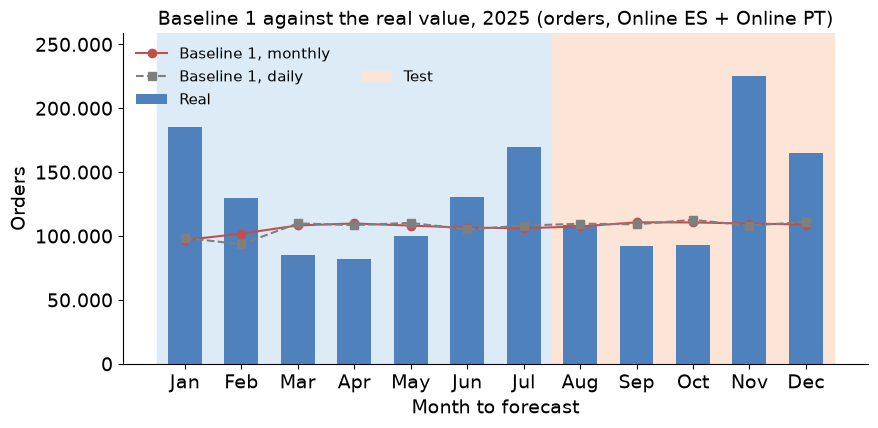

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Uses daily, monthly, TARGETS, run(), scorecard(), split_of() (célula 2), fmt()/reset()/save_table()/save_fig() (célula 1).
# If you restarted the kernel, run as células 1 e 2.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'split_of']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 e 2 e depois esta.")

TARGET = 'orders'          # alvo desta corrida; outros: 'return_units', 'gross_sales', 'net_sales' (ver nota abaixo)
if 'net_sales' not in daily.columns:
    daily['net_sales'] = daily['gross_sales'] - daily['return_value']      # Net = Gross - devoluções registadas no dia

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- Baseline 1: média de todos os meses completos até ao corte ----------
def b1_monthly(h, m, target):
    # h tem só os dias até ao corte (meses completos). Média dos totais mensais.
    return h.groupby('month')[target].sum().mean()

def b1_daily(h, m, target):
    # Average per day across all days up to the cut-off, multiplied by the number of days in the target month
    return h[target].mean() * m.days_in_month

fc = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)

# ---------- controlo à mão (ES + PT, encomendas): média dos meses completos até ao corte ----------
tot_fc = fc.groupby(['method', 'month'])['forecast'].sum().unstack('method')
ctrl = [('2025-09', 'B1 monthly', 110732.5), ('2025-09', 'B1 daily', 109199.9),
        ('2025-11', 'B1 monthly', 109766.0), ('2025-11', 'B1 daily', 108220.0)]
if TARGET == 'orders':
    ck = pd.DataFrame([{'mês-alvo': mth, 'método': meth, 'medido': round(tot_fc.loc[pd.Period(mth, 'M'), meth], 1),
                        'esperado (à mão)': exp, 'bate': abs(tot_fc.loc[pd.Period(mth, 'M'), meth] - exp) < 1.0}
                       for mth, meth, exp in ctrl])
    print('--- Controlo (ES + PT, encomendas): previsões de setembro e novembro de 2025 ---')
    display(ck)

# ---------- erros por método, mercado e período ----------
sc = scorecard(fc, TARGET)
sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
bl2 = pd.DataFrame({'Method': sc['method'], 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                    'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                    'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})
print(f'\n--- Baseline 1: erro por mercado e período (alvo: {TARGET}) ---')
display(bl2)
save_table(bl2, 'BL2', f'Baseline 1: error by market and period (target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT): real, previsão e erro ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tab = pd.DataFrame(act).join(tot_fc[['B1 monthly', 'B1 daily']])
for k in ['B1 monthly', 'B1 daily']:
    tab[k + ' error'] = tab[k] / tab['Real'] - 1
bl3 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index],
                    'Period': [split_of(m) for m in tab.index],
                    'Real': tab['Real'].map(fmt),
                    'B1 monthly': tab['B1 monthly'].map(fmt), 'Error (monthly)': tab['B1 monthly error'].map(pct),
                    'B1 daily': tab['B1 daily'].map(fmt), 'Error (daily)': tab['B1 daily error'].map(pct)})
bl3 = bl3.reset_index(drop=True)      # tira o índice repetido do ecrã
print(f'\n--- Baseline 1: mês a mês, ES + PT (alvo: {TARGET}) ---')
display(bl3)
save_table(bl3, 'BL3', f'Baseline 1: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico: real contra Baseline 1 ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')       # ensaio e teste
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B1 monthly'], color='#C0504D', marker='o', label='Baseline 1, monthly')
ax.plot(x, tab['B1 daily'], color='#7F7F7F', marker='s', linestyle='--', label='Baseline 1, daily')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 1 against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
ax.set_ylim(0, max(tab['Real'].max(), tab[['B1 monthly', 'B1 daily']].max().max()) * 1.15)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label=''), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=11)
fig.tight_layout()
save_fig(fig, 'BL4', f'Baseline 1 against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: cada método filtra a tabela diária uma vez por mês-alvo e mercado (24 vezes), O(d) cada, com d = 731 dias;
# tempo total O(24·d), espaço O(d). O gráfico e as tabelas são O(12).

### 3a. Findings

**Confirmed (full table):**
- All checks match.
- Both versions of Baseline 1 make errors in the same direction in every month except August. They under-forecast January, February, June, July, November and December, and over-forecast March, April, May, September and October.
- The forecast barely changes throughout the year.
- For ES + PT, WAPE is 29.8% (monthly) and 30.8% (daily) during training, and 30.6% (monthly) and 30.4% (daily) during testing. Bias is negative.
- R² is negative in every market and period: Baseline 1 performs worse than simply forecasting the average of the actual months. This is consistent with a forecast that hardly changes over the year.
- For ES + PT, monthly RMSE is around 45,600 orders during training and 58,400 during testing. In the test period, November alone accounts for around 78% of the sum of squared errors, so the test RMSE depends heavily on one month. During training, January accounts for around 54%.
- The difference between monthly and daily versions is one percentage point or less in WAPE across all rows, and almost zero in RMSE and R². There is no consistent winner: the monthly version performs better during training, while the daily version is slightly better during testing for ES + PT.
- In the test period, November and December account for around 82% of the absolute error (monthly version). August is close to the actual result because Baseline 1 forecasts the average of previous months, and August's actual value is close to that average.

## 4. Baseline 2: average of complete months in 2025 available before the cut-off

**What we will do:** For each target month, forecast the value using the average of the complete months in 2025 available before the cut-off, using both monthly and daily calculations. For January and February 2025, there are no complete months from 2025 available at the cut-off, so no forecast can be made. We will compare this model with Baseline 1 only for the months where both forecasts are available (March to December 2025).

**Why:** See whether using only the most recent level of activity (2025) improves on the average of all months, which is pulled down by the lower-volume months in 2024.

**Available history:** from 1 month (March 2025, January only) to 10 months (December 2025, January to October).

**Reference figures (manual/Excel calculation, ES + PT, orders):** March: monthly 185,430.0 and daily 185,430.0; August: monthly 118,673.7 and daily 121,951.9; December: monthly 117,542.8 and daily 119,862.7.

--- Meses de 2025 disponíveis ao corte, por mês-alvo ---


,0,1,2,3,4,5,6,7,8,9,10,11
mês-alvo,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
meses de 2025 disponíveis,0,0,1,2,3,4,5,6,7,8,9,10
tem previsão,False,False,True,True,True,True,True,True,True,True,True,True



--- Controlo (ES + PT, encomendas): previsões de março, agosto e dezembro de 2025 ---


,mês-alvo,método,medido,esperado (à mão),bate
0,2025-03,B2 monthly,185430.0,185430.0,True
1,2025-03,B2 daily,185430.0,185430.0,True
2,2025-08,B2 monthly,118673.7,118673.7,True
3,2025-08,B2 daily,121951.9,121951.9,True
4,2025-12,B2 monthly,117542.8,117542.8,True
5,2025-12,B2 daily,119862.7,119862.7,True


Meses sem previsão da B2 (janeiro e fevereiro): ['2025-01', '2025-02']

--- Baselines 1 e 2 nos meses comuns (março a dezembro de 2025; alvo: orders) ---


,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 monthly,Online ES,Training,5,"24,6%","-7,8%",25.524,"-0,14"
1,B1 daily,Online ES,Training,5,"24,9%","-7,2%",25.222,"-0,11"
2,B2 monthly,Online ES,Training,5,"44,9%","21,0%",43.644,"-2,33"
3,B2 daily,Online ES,Training,5,"45,5%","22,7%",44.022,"-2,39"
4,B1 monthly,Online ES,Test,5,"30,7%","-21,9%",44.957,"-0,34"
5,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
6,B2 monthly,Online ES,Test,5,"33,7%","-12,8%",42.254,"-0,19"
7,B2 daily,Online ES,Test,5,"34,2%","-12,0%",42.495,"-0,20"
8,B1 monthly,Online PT,Training,5,"29,8%","4,2%",9.704,"-0,12"
9,B1 daily,Online PT,Training,5,"30,2%","4,8%",9.597,"-0,10"


Guardado: evidence_baseline/BL5.csv

--- Baseline 2: mês a mês, ES + PT (alvo: orders) ---


,Month,Period,Real,B2 monthly,Error (monthly),B2 daily,Error (daily)
0,Jan 2025,Training,185.430,-,-,-,-
1,Feb 2025,Training,129.645,-,-,-,-
2,Mar 2025,Training,84.939,185.430,"118,3%",185.430,"118,3%"
3,Apr 2025,Training,81.902,157.538,"92,3%",160.208,"95,6%"
4,May 2025,Training,99.901,133.338,"33,5%",137.783,"37,9%"
5,Jun 2025,Training,130.225,120.479,"-7,5%",120.479,"-7,5%"
6,Jul 2025,Training,169.424,116.363,"-31,3%",119.446,"-29,5%"
7,Aug 2025,Test,109.025,118.674,"8,8%",121.952,"11,9%"
8,Sep 2025,Test,92.142,125.924,"36,7%",124.736,"35,4%"
9,Oct 2025,Test,92.795,123.811,"33,4%",126.359,"36,2%"


Guardado: evidence_baseline/BL6.csv
Guardado: evidence_baseline/BL7.png


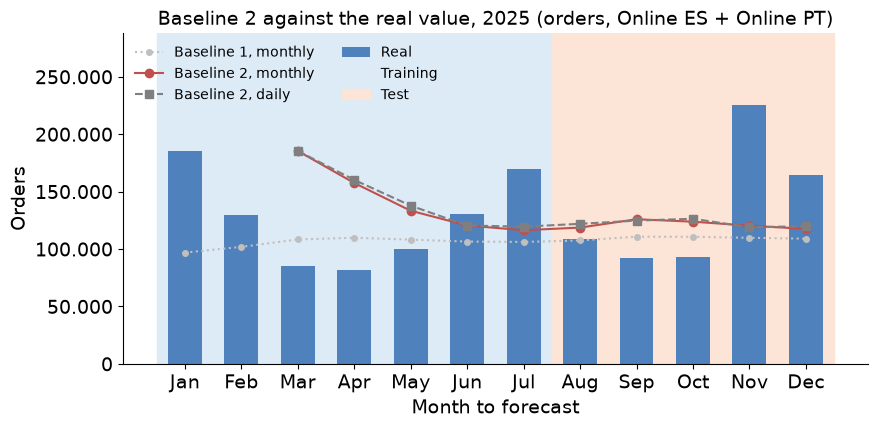

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Uses daily, monthly, TARGETS, run(), scorecard(), split_of() (célula 2), b1_monthly/b1_daily e TARGET (célula 3),
# fmt()/reset()/save_table()/save_fig() (célula 1). Se reiniciaste o kernel, volta a correr as células 1, 2 e 3.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'split_of', 'b1_monthly', 'b1_daily', 'TARGET']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 2 e 3 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- Baseline 2: média só dos meses completos de 2025 até ao corte ----------
SINCE = pd.Timestamp('2025-01-01')

def b2_monthly(h, m, target):
    # Only 2025 months; if no complete 2025 month is available at the cut-off (January and February 2025), no forecast is produced.
    hh = h[h['day'] >= SINCE]
    if hh.empty:
        return None
    return hh.groupby('month')[target].sum().mean()

def b2_daily(h, m, target):
    hh = h[h['day'] >= SINCE]
    if hh.empty:
        return None
    return hh[target].mean() * m.days_in_month

fc_b2 = pd.concat([run('B2 monthly', b2_monthly, TARGET), run('B2 daily', b2_daily, TARGET)], ignore_index=True)
fc_b1 = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)

# ---------- quantos meses de histórico tem a B2 em cada mês-alvo ----------
hist = pd.DataFrame({'mês-alvo': [str(m) for m in TARGETS],
                     'meses de 2025 disponíveis': [max(0, (pd.Period(m, 'M') - 2).month if (pd.Period(m, 'M') - 2).year == 2025 else 0) for m in TARGETS],
                     'tem previsão': [m in set(fc_b2.loc[fc_b2['method'] == 'B2 monthly', 'month']) for m in TARGETS]})
print('--- Meses de 2025 disponíveis ao corte, por mês-alvo ---')
display(hist.T)

# ---------- controlo à mão (ES + PT, encomendas) ----------
tot_b2 = fc_b2.groupby(['method', 'month'])['forecast'].sum().unstack('method')
ctrl = [('2025-03', 'B2 monthly', 185430.0), ('2025-03', 'B2 daily', 185430.0),
        ('2025-08', 'B2 monthly', 118673.7), ('2025-08', 'B2 daily', 121951.9),
        ('2025-12', 'B2 monthly', 117542.8), ('2025-12', 'B2 daily', 119862.7)]
if TARGET == 'orders':
    ck = pd.DataFrame([{'mês-alvo': mth, 'método': meth, 'medido': round(tot_b2.loc[pd.Period(mth, 'M'), meth], 1),
                        'esperado (à mão)': exp, 'bate': abs(tot_b2.loc[pd.Period(mth, 'M'), meth] - exp) < 1.0}
                       for mth, meth, exp in ctrl])
    print('\n--- Controlo (ES + PT, encomendas): previsões de março, agosto e dezembro de 2025 ---')
    display(ck)
    print('Meses sem previsão da B2 (janeiro e fevereiro):',
          [str(m) for m in TARGETS if m not in set(fc_b2.loc[fc_b2['method'] == 'B2 monthly', 'month'])])

# ---------- comparação justa: B1 e B2 só nos meses em que as duas existem ----------
def scorecard_common(fc, target, methods):
    # compara os métodos só nos meses (por mercado) em que TODOS têm previsão, para o WAPE ser comparável
    sub = fc[fc['method'].isin(methods)]
    n = sub.groupby(['mark', 'month'])['method'].nunique()
    ok = n[n == len(methods)].index
    sub = sub.set_index(['mark', 'month']).loc[ok].reset_index()
    return scorecard(sub, target)

fc_all = pd.concat([fc_b1, fc_b2], ignore_index=True)
methods = ['B1 monthly', 'B1 daily', 'B2 monthly', 'B2 daily']
sc = scorecard_common(fc_all, TARGET, methods)
sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
bl5 = pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                    'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                    'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})
print(f'\n--- Baselines 1 e 2 nos meses comuns (março a dezembro de 2025; alvo: {TARGET}) ---')
display(bl5)
save_table(bl5, 'BL5', f'Baselines 1 and 2 compared on the same months (March to December 2025; target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT) da Baseline 2 ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tab = pd.DataFrame(act).join(tot_b2).join(fc_b1.groupby(['method', 'month'])['forecast'].sum().unstack('method')[['B1 monthly']])
def cell_or_dash(v):
    return '-' if pd.isna(v) else fmt(v)
def err_or_dash(f, r):
    return '-' if pd.isna(f) else pct(f / r - 1)
bl6 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index],
                    'Period': [split_of(m) for m in tab.index],
                    'Real': tab['Real'].map(fmt),
                    'B2 monthly': tab['B2 monthly'].map(cell_or_dash),
                    'Error (monthly)': [err_or_dash(f, r) for f, r in zip(tab['B2 monthly'], tab['Real'])],
                    'B2 daily': tab['B2 daily'].map(cell_or_dash),
                    'Error (daily)': [err_or_dash(f, r) for f, r in zip(tab['B2 daily'], tab['Real'])]}).reset_index(drop=True)
print(f'\n--- Baseline 2: mês a mês, ES + PT (alvo: {TARGET}) ---')
display(bl6)
save_table(bl6, 'BL6', f'Baseline 2: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico: real contra Baseline 2 (com a Baseline 1 mensal como referência) ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B1 monthly'], color='#BFBFBF', linestyle=':', marker='o', markersize=4, label='Baseline 1, monthly')
ax.plot(x, tab['B2 monthly'], color='#C0504D', marker='o', label='Baseline 2, monthly')   # NaN em jan e fev: a linha começa em março
ax.plot(x, tab['B2 daily'], color='#7F7F7F', marker='s', linestyle='--', label='Baseline 2, daily')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 2 against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
top = np.nanmax(tab[['Real', 'B1 monthly', 'B2 monthly', 'B2 daily']].to_numpy(dtype=float))
ax.set_ylim(0, top * 1.28)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
fig.tight_layout()
save_fig(fig, 'BL7', f'Baseline 2 against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: igual à célula 3: 24 filtros O(d) à tabela diária (d = 731) por método; as comparações e tabelas são O(12).

### 4a. Findings

**Confirmed (full table):**
- All checks match.
- B2 reduces B1's bias in the test months, but performs worse in March, April and May because its average is based on only 1 to 3 months, and January (a Clearance month) is unusually high.
- Across the same 10 months (March to December), B2 does not improve on B1 in any period. The gap is larger during training than during testing.
- During training, B2 is also worse in RMSE and R². Around 80% of its total squared error comes from March and April, when the average is based on only 1 or 2 months.
- During testing, bias improves but WAPE gets worse because B2 over-forecasts the weaker months of September and October. RMSE and R² improve. RMSE is driven mainly by November (around 71% of B2's total squared error), when B2 makes a smaller error than B1 (−46.5% compared with −51.2%).
- R² is negative for every row in both baselines.
- During testing, November and December account for around 67% of B2's absolute error (compared with around 82% for B1), while September and October account for around 29%.
- B2's forecast settles from June onwards and becomes almost flat, so it does not follow seasonal patterns.
- Portugal is more affected than Spain during training.
- The difference between monthly and daily versions is less than 1 percentage point in every row. In March, both versions give the same result (185,430) because January and March both have 31 days.

## 5. Baseline 3: same month last year × recent growth

**What we will do:** For each target month, take the value from the same month in the previous year and multiply it by the most recent growth rate. The growth rate is calculated by dividing the total for the 3 months available before the cut-off by the total for the same 3 months one year earlier. We will test both monthly and daily versions (each day uses the value from 364 days earlier, which is the same day of the week). We will compare B3 with Baselines 1 and 2 only for the months where all three forecasts are available (May to December 2025).

**Why:** See whether adding the seasonal pattern from the previous year improves on baselines that only look at the overall level of activity.

**Months with forecasts:** May to December 2025 (8 months: 3 during training and 5 during testing). There is not enough 2024 data to calculate the growth rate for January to April.

**Reference figures (manual/Excel calculation, ES + PT, orders, monthly B3, each market using its own growth rate):** May 141,180.2; August 115,441.9; November 203,635.8.

Meses-alvo com previsão da B3 (mensal): ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] (esperado: maio a dezembro de 2025)
Meses-alvo com previsão da B3 (diária):  ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12']

--- Controlo 1 (ES + PT, encomendas): B3 mensal calculada à mão ---


,mês-alvo,método,medido,esperado (à mão),bate
0,2025-05,B3 monthly,141180.2,141180.2,True
1,2025-08,B3 monthly,115441.9,115441.9,True
2,2025-11,B3 monthly,203635.8,203635.8,True



--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---


,mês-alvo,mercado,função,ciclo dia a dia,bate
0,2025-05,Online ES,112182.90,112182.90,True
1,2025-08,Online ES,80953.71,80953.71,True
2,2025-11,Online ES,160019.27,160019.27,True



--- Baselines 1, 2 e 3 nos meses comuns (maio a dezembro de 2025; alvo: orders) ---


,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 monthly,Online ES,Training,3,"23,8%","-22,1%",29.988,"-1,32"
1,B1 daily,Online ES,Training,3,"24,1%","-21,4%",29.513,"-1,25"
2,B2 monthly,Online ES,Training,3,"23,6%","-10,3%",26.236,"-0,77"
3,B2 daily,Online ES,Training,3,"23,9%","-8,5%",26.030,"-0,75"
4,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,39"
5,B3 daily,Online ES,Training,3,"24,9%","15,3%",26.485,"-0,81"
6,B1 monthly,Online ES,Test,5,"30,7%","-21,9%",44.957,"-0,34"
7,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
8,B2 monthly,Online ES,Test,5,"33,7%","-12,8%",42.254,"-0,19"
9,B2 daily,Online ES,Test,5,"34,2%","-12,0%",42.495,"-0,20"


Guardado: evidence_baseline/BL8.csv

--- Baseline 3: mês a mês, ES + PT (alvo: orders); "Growth applied" = previsão / mês do ano anterior ---


,Month,Period,Real,Same month last year,Growth applied,B3 monthly,Error (monthly),B3 daily,Error (daily)
0,Jan 2025,Training,185.430,113.632,-,-,-,-,-
1,Feb 2025,Training,129.645,70.181,-,-,-,-,-
2,Mar 2025,Training,84.939,55.944,-,-,-,-,-
3,Apr 2025,Training,81.902,73.202,-,-,-,-,-
4,May 2025,Training,99.901,84.318,"1,67",141.180,"41,3%",146.759,"46,9%"
5,Jun 2025,Training,130.225,105.358,"1,49",157.100,"20,6%",163.283,"25,4%"
6,Jul 2025,Training,169.424,121.764,"1,25",151.950,"-10,3%",150.051,"-11,4%"
7,Aug 2025,Test,109.025,97.574,"1,18",115.442,"5,9%",111.732,"2,5%"
8,Sep 2025,Test,92.142,84.819,"1,28",108.874,"18,2%",109.942,"19,3%"
9,Oct 2025,Test,92.795,91.371,"1,26",115.197,"24,1%",113.082,"21,9%"


Guardado: evidence_baseline/BL9.csv
Guardado: evidence_baseline/BL10.png


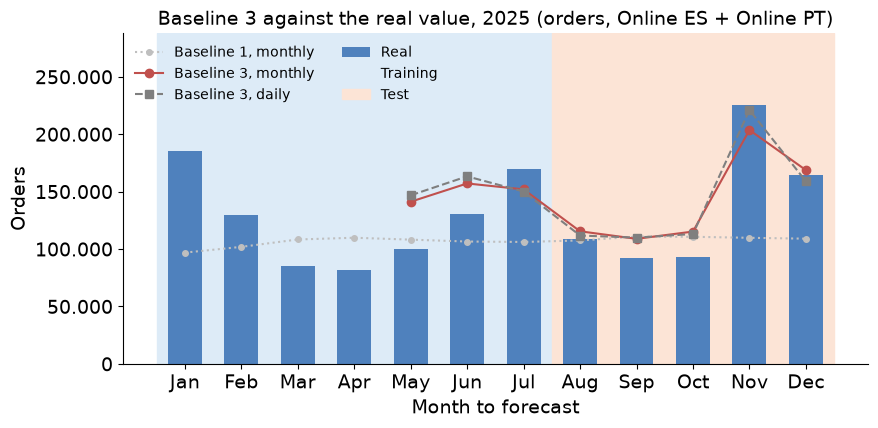

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Uses daily, monthly, TARGETS, run(), scorecard(), split_of(), cutoff_date() (célula 2), b1_* e TARGET (célula 3),
# b2_*, scorecard_common() (célula 4), fmt()/reset()/save_table()/save_fig() (célula 1).
# If you restarted the kernel, run as células 1 a 4.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'split_of', 'cutoff_date', 'b1_monthly', 'b1_daily',
             'b2_monthly', 'b2_daily', 'scorecard_common', 'TARGET']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 a 4 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')
K = 3          # nº de meses recentes usados para medir o crescimento (decisão do grupo: 3)

# ---------- Baseline 3: mesmo mês (ou dia da semana) do ano anterior x crescimento recente ----------
def b3_monthly(h, m, target):
    # Forecast = value for the same month last year × (total for the K months up to the cut-off / total for the same K months one year earlier)
    mt = h.groupby('month')[target].sum()
    last = pd.Period(m, 'M') - 2                          # último mês completo (corte)
    recent = [last - i for i in range(K)]
    prior = [p - 12 for p in recent]
    base = pd.Period(m, 'M') - 12                         # mesmo mês do ano anterior
    if any(p not in mt.index for p in recent + prior + [base]):
        return None                                       # sem histórico suficiente (antes de maio de 2025)
    return mt[base] * mt[recent].sum() / mt[prior].sum()

def b3_daily(h, m, target):
    # igual, mas ao dia: cada dia do mês-alvo copia o dia 364 dias antes (52 semanas: mesmo dia da semana).
    # O crescimento compara os K meses recentes com os mesmos dias 364 dias antes.
    s = h.set_index('day')[target]
    start = (pd.Period(m, 'M') - 2 - (K - 1)).start_time
    win = pd.date_range(start, cutoff_date(m))
    month_days = pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize())
    shift = pd.Timedelta(days=364)
    if (win - shift).min() < s.index.min() or (month_days - shift).min() < s.index.min():
        return None
    growth = s.reindex(win).sum() / s.reindex(win - shift).sum()
    return s.reindex(month_days - shift).sum() * growth

fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)
fc_b1 = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)
fc_b2 = pd.concat([run('B2 monthly', b2_monthly, TARGET), run('B2 daily', b2_daily, TARGET)], ignore_index=True)
avail = sorted(set(fc_b3.loc[fc_b3['method'] == 'B3 monthly', 'month']))
print('Meses-alvo com previsão da B3 (mensal):', [str(m) for m in avail], '(esperado: maio a dezembro de 2025)')
print('Meses-alvo com previsão da B3 (diária): ', [str(m) for m in sorted(set(fc_b3.loc[fc_b3['method'] == 'B3 daily', 'month']))])

# ---------- controlo 1: valores calculados à mão (ES + PT, encomendas; cada mercado com o seu crescimento) ----------
tot_b3 = fc_b3.groupby(['method', 'month'])['forecast'].sum().unstack('method')
ctrl = [('2025-05', 141180.2), ('2025-08', 115441.9), ('2025-11', 203635.8)]
if TARGET == 'orders':
    ck = pd.DataFrame([{'mês-alvo': mth, 'método': 'B3 monthly', 'medido': round(tot_b3.loc[pd.Period(mth, 'M'), 'B3 monthly'], 1),
                        'esperado (à mão)': exp, 'bate': abs(tot_b3.loc[pd.Period(mth, 'M'), 'B3 monthly'] - exp) < 1.0}
                       for mth, exp in ctrl])
    print('\n--- Controlo 1 (ES + PT, encomendas): B3 mensal calculada à mão ---')
    display(ck)

# ---------- controlo 2: a versão diária recalculada por outro caminho (ciclo dia a dia) ----------
def b3_daily_loop(h, m, target):
    s = dict(zip(h['day'], h[target]))
    cut = cutoff_date(m)
    d = (pd.Period(m, 'M') - 2 - (K - 1)).start_time
    num = den = 0.0
    while d <= cut:
        num += s[d]; den += s[d - pd.Timedelta(days=364)]
        d += pd.Timedelta(days=1)
    base = sum(s[d - pd.Timedelta(days=364)] for d in pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize()))
    return base * num / den

rows = []
for mth in ['2025-05', '2025-08', '2025-11']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
    a, b = b3_daily(hh, mm, TARGET), b3_daily_loop(hh, mm, TARGET)
    rows.append({'mês-alvo': mth, 'mercado': 'Online ES', 'função': round(a, 2), 'ciclo dia a dia': round(b, 2), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---')
display(pd.DataFrame(rows))

# ---------- comparação justa: B1, B2 e B3 só nos meses em que as três existem ----------
fc_all = pd.concat([fc_b1, fc_b2, fc_b3], ignore_index=True)
methods = ['B1 monthly', 'B1 daily', 'B2 monthly', 'B2 daily', 'B3 monthly', 'B3 daily']
sc = scorecard_common(fc_all, TARGET, methods)
sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
bl8 = pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                    'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                    'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})
print(f'\n--- Baselines 1, 2 e 3 nos meses comuns (maio a dezembro de 2025; alvo: {TARGET}) ---')
display(bl8)
save_table(bl8, 'BL8', f'Baselines 1, 2 and 3 compared on the same months (May to December 2025; target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT) da Baseline 3 ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
prev_year = monthly.groupby('month')[TARGET].sum()
tab = pd.DataFrame(act).join(tot_b3)
tab['Same month last year'] = [prev_year.get(m - 12, np.nan) for m in tab.index]
tab['Growth ratio'] = [np.nan if pd.isna(f) else f / b for f, b in zip(tab['B3 monthly'], tab['Same month last year'])]
b1m = fc_b1[fc_b1['method'] == 'B1 monthly'].groupby('month')['forecast'].sum()
tab = tab.join(b1m.rename('B1 monthly'))
def dash(v):
    return '-' if pd.isna(v) else fmt(v)
def err(f, r):
    return '-' if pd.isna(f) else pct(f / r - 1)
bl9 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index],
                    'Period': [split_of(m) for m in tab.index],
                    'Real': tab['Real'].map(fmt),
                    'Same month last year': tab['Same month last year'].map(dash),
                    'Growth applied': tab['Growth ratio'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ',')),
                    'B3 monthly': tab['B3 monthly'].map(dash),
                    'Error (monthly)': [err(f, r) for f, r in zip(tab['B3 monthly'], tab['Real'])],
                    'B3 daily': tab['B3 daily'].map(dash),
                    'Error (daily)': [err(f, r) for f, r in zip(tab['B3 daily'], tab['Real'])]}).reset_index(drop=True)
print(f'\n--- Baseline 3: mês a mês, ES + PT (alvo: {TARGET}); "Growth applied" = previsão / mês do ano anterior ---')
display(bl9)
save_table(bl9, 'BL9', f'Baseline 3: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico: real contra Baselines 1 e 3 ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')       # treino e teste
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B1 monthly'], color='#BFBFBF', linestyle=':', marker='o', markersize=4, label='Baseline 1, monthly')
ax.plot(x, tab['B3 monthly'], color='#C0504D', marker='o', label='Baseline 3, monthly')   # NaN antes de maio: a linha começa em maio
ax.plot(x, tab['B3 daily'], color='#7F7F7F', marker='s', linestyle='--', label='Baseline 3, daily')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 3 against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
top = np.nanmax(tab[['Real', 'B1 monthly', 'B3 monthly', 'B3 daily']].to_numpy(dtype=float))
ax.set_ylim(0, top * 1.28)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
fig.tight_layout()
save_fig(fig, 'BL10', f'Baseline 3 against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: 24 filtros O(d) à tabela diária (d = 731) por método; a B3 diária acrescenta uma série indexada por dia,
# O(d) em tempo e espaço, por mês-alvo e mercado; as comparações e tabelas são O(12).

### 5a. Findings

**Confirmed (full table):**
- All checks match.
- During testing, B3 is clearly the strongest baseline so far. For ES + PT, WAPE is 10.4% (monthly) and 7.4% (daily), compared with 30.6% and 30.4% for B1, and 33.1% and 33.6% for B2. Bias is small and positive (+4.1% and +4.6%).
- During testing, B3 also performs best in RMSE and R². It is the only baseline with a positive R² in the test period.
- During training (only 3 months: May, June and July), the advantage is smaller: monthly B3 is 21.4%, compared with 23.8% for B1 and 24.1% for B2. Daily B3 (24.9%) performs worse than both in WAPE. B3's bias changes direction and becomes positive, which is the direction we would rather avoid.
- During training, RMSE and R² also identify monthly B3 as the best option. Daily B3 is the exception: its WAPE is worse, but its RMSE and R² are better than B1 and B2. With only 3 months, R² is not very meaningful: it is negative for every method in ES + PT.
- B3 clearly improves the test results and slightly under-forecasts November (−9.5% in the monthly version and −1.8% in the daily version).
- The error comes from the difference between recent growth and the growth in the target month itself. For example, the growth rate applied in May was 1.67, while the actual growth was 1.18; in October, the figures were 1.26 and 1.02.
- During testing, September and October account for around 55% of the absolute error for monthly B3, and November accounts for around 30%. For B1 and B2, most of the error came from November and December. RMSE is more affected by October (around 39% of the total squared error) and November (around 35%).
- Spain and Portugal behave similarly during testing. Portugal has a higher over-forecast.
- Monthly versus daily: the monthly version performs better during training, while the daily version performs better during testing. RMSE and R² tell the same story. The evidence is mixed, and the training period contains only 3 months.

## 6. Baseline 4: average for normal days × campaign factor (daily only)

**What we will do:**
a) Mark the days covered by campaigns that follow the Online ES and Online PT calendar, using the `events` table (Black Friday, Christmas, Mother's Day, Reyes, Valentine's Day and Easter/Holy Week).
b) For each target month, use the data available before the cut-off to estimate the level for a normal day (the average for days without a campaign) and a factor for each campaign (orders on campaign days divided by the average for normal days in the previous 28 days).
c) Forecast each day in the target month using the normal-day level, or the normal-day level multiplied by the campaign factor, and add the daily forecasts to get the monthly total.
d) Compare the result with daily B1 (which does not include campaigns) and with the other baselines.

**Why:** Measure the value of knowing the dates of campaigns that follow a fixed calendar (B1 without campaign information versus B4 with campaign information).

**Decisions:**
- Included campaigns are those known at the start of the year because they follow a calendar. Clearance, free shipping, Special prices, Stock 1 and reactive campaigns are excluded because Parfois only knows some of them by the cut-off date.
- The dates of these campaigns in the target month are assumed to be known in advance (from the calendar). Campaign factors use only days available before the cut-off.
- If there are no previous campaign days to measure a factor (for example, Easter in April 2025, if Easter has not occurred before the cut-off), the factor is set to 1.00.
- Only a daily version is possible because campaigns have specific dates.

**Reference checks:** With no campaigns included, B4 gives exactly the same result as daily B1; there are 810 rows in the `events` table; Black Friday should have 6 days per year and market (26/11 to 01/12 in 2024 and 25/11 to 30/11 in 2025).

Linhas de events: 810 (esperado 810)

--- Dias de campanha marcados (famílias escolhidas) ---


,Campaign,Year,Market,Days,First day,Last day
0,Black Friday,2024,Online ES,6,2024-11-26,2024-12-01
1,Black Friday,2024,Online PT,6,2024-11-26,2024-12-01
2,Black Friday,2025,Online ES,6,2025-11-25,2025-11-30
3,Black Friday,2025,Online PT,6,2025-11-25,2025-11-30
4,Christmas,2024,Online ES,4,2024-12-17,2024-12-20
5,Christmas,2024,Online PT,4,2024-12-17,2024-12-20
6,Christmas,2025,Online ES,4,2025-12-18,2025-12-21
7,Christmas,2025,Online PT,4,2025-12-18,2025-12-21
8,Easter and Holy Week,2024,Online ES,17,2024-03-16,2024-04-01
9,Easter and Holy Week,2024,Online PT,17,2024-03-16,2024-04-01


Controlo visual: pelo notebook de exploração (20a e 22a) a Black Friday devia ter 6 dias por ano e mercado (26/11 a 01/12 de 2024 e 25/11 a 30/11 de 2025); confirma na tabela.
Guardado: evidence_baseline/BL11.csv

--- Controlo 1: B4 sem campanhas contra B1 diária ---
Diferença máxima (encomendas): 0.000000000 (esperado 0)

--- Controlo 2: B4 (função) contra o mesmo cálculo com ciclos simples ---


,mês-alvo,mercado,função,ciclos simples,bate
0,2025-05,Online ES,76495.84,76495.84,True
1,2025-11,Online ES,166876.41,166876.41,True
2,2025-12,Online ES,85325.79,85325.79,True



--- Factores aplicados por mês-alvo (só com dados até ao corte) ---


,Month to forecast,Market,Campaign,Campaign days in the month,Factor applied,Days measured in the history,Note
0,Jan 2025,Online ES,Reyes,2,"1,00",0,"not measured: factor 1,00"
1,Feb 2025,Online ES,Valentines,3,"0,82",4,measured
2,Feb 2025,Online PT,Valentines,3,"0,98",4,measured
3,Apr 2025,Online ES,Easter and Holy Week,17,"0,91",17,measured
4,Apr 2025,Online ES,Mothers Day,5,"1,33",3,measured
5,Apr 2025,Online PT,Easter and Holy Week,17,"0,89",17,measured
6,Apr 2025,Online PT,Mothers Day,6,"1,30",3,measured
7,Nov 2025,Online ES,Black Friday,6,"6,72",6,measured
8,Nov 2025,Online PT,Black Friday,6,"8,21",6,measured
9,Dec 2025,Online ES,Christmas,4,"1,55",4,measured


... (3 outputs left out)

,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 monthly,Online ES,Training,3,"23,8%","-22,1%",29.988,"-1,32"
1,B1 daily,Online ES,Training,3,"24,1%","-21,4%",29.513,"-1,25"
2,B2 monthly,Online ES,Training,3,"23,6%","-10,3%",26.236,"-0,77"
3,B2 daily,Online ES,Training,3,"23,9%","-8,5%",26.030,"-0,75"
4,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,39"
5,B3 daily,Online ES,Training,3,"24,9%","15,3%",26.485,"-0,81"
6,B4 daily,Online ES,Training,3,"24,7%","-24,7%",31.681,"-1,59"
7,B1 monthly,Online ES,Test,5,"30,7%","-21,9%",44.957,"-0,34"
8,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
9,B2 monthly,Online ES,Test,5,"33,7%","-12,8%",42.254,"-0,19"


Guardado: evidence_baseline/BL14.csv

--- Baseline 4: mês a mês, ES + PT (alvo: orders) ---


,Month,Period,Real,B1 daily,Error (B1),B4 daily,Error (B4)
0,Jan 2025,Training,185.430,98.591,"-46,8%",92.707,"-50,0%"
1,Feb 2025,Training,129.645,93.521,"-27,9%",85.313,"-34,2%"
2,Mar 2025,Training,84.939,109.935,"29,4%",103.660,"22,0%"
3,Apr 2025,Training,81.902,108.531,"32,5%",103.043,"25,8%"
4,May 2025,Training,99.901,110.299,"10,4%",104.554,"4,7%"
5,Jun 2025,Training,130.225,105.208,"-19,2%",101.097,"-22,4%"
6,Jul 2025,Training,169.424,108.186,"-36,1%",104.158,"-38,5%"
7,Aug 2025,Test,109.025,109.633,"0,6%",106.048,"-2,7%"
8,Sep 2025,Test,92.142,109.200,"18,5%",106.324,"15,4%"
9,Oct 2025,Test,92.795,112.646,"21,4%",109.820,"18,3%"


Guardado: evidence_baseline/BL15.csv
Guardado: evidence_baseline/BL16.png


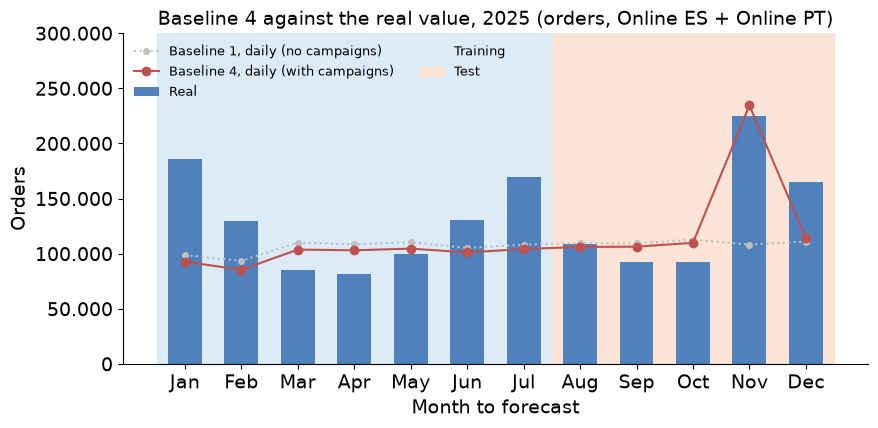

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Uses daily, monthly, TARGETS, run(), scorecard(), split_of() (célula 2), b1_*, b2_*, b3_*, TARGET, scorecard_common()
# (células 3 a 5) e files(), MARKETS, START, END, mk_in, mk_values, fmt()/reset()/save_table()/save_fig() (célula 1).
# If you restarted the kernel, run as células 1 a 5.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'split_of', 'history', 'b1_monthly', 'b1_daily',
             'b2_monthly', 'b2_daily', 'b3_monthly', 'b3_daily', 'scorecard_common', 'TARGET',
             'files', 'MARKETS', 'START', 'END', 'mk_in', 'mk_values']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 a 5 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- Campaign selection (decision: calendar-based campaigns known at the start of the year) ----------
FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Easter and Holy Week']     # ordem = prioridade se dois eventos caírem no mesmo dia
WIN, MIN_REF = 28, 7     # referência de cada dia de campanha: média dos dias normais dos 28 dias anteriores (mínimo 7 dias)

# ---------- eventos: leitura, nomes limpos e família (mesmas regras do notebook de exploração) ----------
lst_ev = ', '.join(f"'{f}'" for f in files('events'))
fam_in = ', '.join(f"'{f}'" for f in FAMS)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE ev_b4 AS
SELECT mark, clean_name, start_d, end_d, (end_d >= start_d) AS valid,
  CASE
    WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
    WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
    WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
    WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
    WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
    WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
    WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
    WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
    WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
    WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
    WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
    WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
    ELSE 'Other'
  END AS family
FROM (SELECT MARK_COD AS mark, regexp_replace(trim(EVENT), '\\s+', ' ', 'g') AS clean_name,
             try_cast(START_DATE AS DATE) AS start_d, try_cast(END_DATE AS DATE) AS end_d
      FROM read_parquet([{lst_ev}]))
""")
n_ev = con.execute("SELECT count(*) FROM ev_b4").fetchall()[0][0]
print('Linhas de events:', fmt(n_ev), '(esperado 810)')

# ---------- dias de campanha por mercado: eventos com mercado + linhas da Black Friday sem mercado ----------
# Regra do notebook de exploração (célula 21a): as linhas da Black Friday sem mercado valem para todos os mercados com eventos (exceto Online MX).
# As linhas sem mercado das outras famílias não se aplicam a nenhum mercado. Linhas com fim anterior ao início ficam fora.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE camp_days AS
WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
rows_m AS (
  SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
    SELECT mark, family,
           unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                  CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
    FROM ev_b4 WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
rows_g AS (
  SELECT mk.mark, g.family, g.day FROM (
    SELECT family, CAST(day_ts AS DATE) AS day FROM (
      SELECT family,
             unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                    CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
      FROM ev_b4 WHERE valid AND mark IS NULL AND family = 'Black Friday' AND 'Black Friday' IN ({fam_in}))) g
  CROSS JOIN mk)
SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
""")
camp = con.sql("SELECT mark, family, day FROM camp_days").df()
camp['day'] = pd.to_datetime(camp['day'])
camp['p'] = camp['family'].map({f: i for i, f in enumerate(FAMS)})
camp = camp.sort_values(['mark', 'day', 'p']).drop_duplicates(['mark', 'day']).drop(columns='p').reset_index(drop=True)

# Prova BL11: dias de campanha usados, por família, ano e mercado
camp['year'] = camp['day'].dt.year
info = camp.groupby(['family', 'year', 'mark']).agg(days=('day', 'count'), first=('day', 'min'), last=('day', 'max')).reset_index()
bl11 = pd.DataFrame({'Campaign': info['family'], 'Year': info['year'], 'Market': info['mark'], 'Days': info['days'],
                     'First day': info['first'].dt.strftime('%Y-%m-%d'), 'Last day': info['last'].dt.strftime('%Y-%m-%d')})
print('\n--- Dias de campanha marcados (famílias escolhidas) ---')
display(bl11)
print('Controlo visual: pelo notebook de exploração (20a e 22a) a Black Friday devia ter 6 dias por ano e mercado '
      '(26/11 a 01/12 de 2024 e 25/11 a 30/11 de 2025); confirma na tabela.')
save_table(bl11, 'BL11', 'Campaign days used by Baseline 4 (campaigns that follow the calendar), by campaign, year and market', 'whole table')

# ---------- Baseline 4: nível dos dias normais x factor de cada dia de campanha ----------
def make_b4(camp_df):
    cmap = {mk: dict(zip(g['day'], g['family'])) for mk, g in camp_df.groupby('mark')}
    def parts(h, m, target):
        mk = h['mark'].iloc[0]
        fam_of = cmap.get(mk, {})
        s = h.set_index('day')[target].sort_index()
        flag = np.array([d in fam_of for d in s.index])
        normal = s[~flag]
        level = normal.mean()                                  # nível: média diária dos dias sem campanha até ao corte
        num, den, cnt = {}, {}, {}
        for d in s.index[flag]:                                # factor: real / referência, só com dias até ao corte
            w = normal.loc[d - pd.Timedelta(days=WIN): d - pd.Timedelta(days=1)]
            if len(w) >= MIN_REF:
                f = fam_of[d]
                num[f] = num.get(f, 0.0) + s[d]; den[f] = den.get(f, 0.0) + w.mean(); cnt[f] = cnt.get(f, 0) + 1
        factor = {f: num[f] / den[f] for f in num}
        days = pd.date_range(m.start_time, m.end_time.normalize())
        fam_days = {}
        for d in days:
            f = fam_of.get(d)
            if f:
                fam_days[f] = fam_days.get(f, 0) + 1
        total = level * sum((factor.get(fam_of[d], 1.0) if d in fam_of else 1.0) for d in days)   # sem factor medido: 1,0
        return {'level': level, 'factor': factor, 'n': cnt, 'fam_days': fam_days, 'forecast': total}
    def b4(h, m, target):
        return parts(h, m, target)['forecast']
    return b4, parts

b4_daily, b4_parts = make_b4(camp)
fc_b4 = run('B4 daily', b4_daily, TARGET)

# ---------- controlo 1: sem campanhas, a B4 tem de dar exatamente a B1 diária ----------
b4_none, _ = make_b4(camp.iloc[0:0])
t_none = run('B4 without campaigns', b4_none, TARGET).set_index(['mark', 'month'])['forecast']
t_b1 = run('B1 daily', b1_daily, TARGET).set_index(['mark', 'month'])['forecast']
print('\n--- Controlo 1: B4 sem campanhas contra B1 diária ---')
print('Diferença máxima (encomendas):', f"{(t_none - t_b1).abs().max():.9f}", '(esperado 0)')

# ---------- controlo 2: a B4 recalculada por outro caminho (ciclos simples) ----------
def b4_loop(h, m, target):
    mk = h['mark'].iloc[0]
    sub = camp[camp['mark'] == mk]
    fam_of = dict(zip(sub['day'], sub['family']))
    y = dict(zip(h['day'], h[target]))
    normal_days = [d for d in y if d not in fam_of]
    level = sum(y[d] for d in normal_days) / len(normal_days)
    num, den = {}, {}
    for d in y:
        if d in fam_of:
            vals = []
            for k in range(1, WIN + 1):
                dd = d - pd.Timedelta(days=k)
                if dd in y and dd not in fam_of:
                    vals.append(y[dd])
            if len(vals) >= MIN_REF:
                num[fam_of[d]] = num.get(fam_of[d], 0) + y[d]
                den[fam_of[d]] = den.get(fam_of[d], 0) + sum(vals) / len(vals)
    total, d = 0.0, m.start_time
    while d <= m.end_time.normalize():
        f = fam_of.get(d)
        total += (level * (num[f] / den[f] if f in num else 1.0)) if f else level
        d += pd.Timedelta(days=1)
    return total

rows = []
for mth in ['2025-05', '2025-11', '2025-12']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
    a, b = b4_daily(hh, mm, TARGET), b4_loop(hh, mm, TARGET)
    rows.append({'mês-alvo': mth, 'mercado': 'Online ES', 'função': round(a, 2), 'ciclos simples': round(b, 2), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 2: B4 (função) contra o mesmo cálculo com ciclos simples ---')
display(pd.DataFrame(rows))

# ---------- factores aplicados em cada mês-alvo (BL12) ----------
rows = []
for m in TARGETS:
    h = history(daily, m)
    for mk in MARKETS:
        p = b4_parts(h[h['mark'] == mk], m, TARGET)
        for fam, nd in p['fam_days'].items():
            measured = p['n'].get(fam, 0)
            rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Campaign': fam, 'Campaign days in the month': nd,
                         'Factor applied': (f"{p['factor'][fam]:.2f}".replace('.', ',') if fam in p['factor'] else '1,00'),
                         'Days measured in the history': measured,
                         'Note': 'measured' if fam in p['factor'] else 'not measured: factor 1,00'})
bl12 = pd.DataFrame(rows)
print('\n--- Factores aplicados por mês-alvo (só com dados até ao corte) ---')
display(bl12)
save_table(bl12, 'BL12', 'Baseline 4: campaign factor applied in each month to forecast, by market (target: ' + TARGET + ')', 'whole table')

# ---------- B1 diária contra B4 diária (com e sem campanhas), nos 12 meses ----------
fc_b1 = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)
fc_b2 = pd.concat([run('B2 monthly', b2_monthly, TARGET), run('B2 daily', b2_daily, TARGET)], ignore_index=True)
fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)
fc_all = pd.concat([fc_b1, fc_b2, fc_b3, fc_b4], ignore_index=True)

def tidy(sc, methods):
    sc = sc.copy()
    sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
    sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
    sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
    sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
    return pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                         'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                         'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})

pair = ['B1 daily', 'B4 daily']
bl13 = tidy(scorecard_common(fc_all, TARGET, pair), pair)
print(f'\n--- Sem campanhas (B1 diária) contra com campanhas (B4 diária), 12 meses (alvo: {TARGET}) ---')
display(bl13)
save_table(bl13, 'BL13', f'Without campaigns (Baseline 1, daily) against with campaigns (Baseline 4, daily), 2025 (target: {TARGET})', 'whole table')

# ---------- todas as baselines nos meses comuns (maio a dezembro) ----------
methods = ['B1 monthly', 'B1 daily', 'B2 monthly', 'B2 daily', 'B3 monthly', 'B3 daily', 'B4 daily']
bl14 = tidy(scorecard_common(fc_all, TARGET, methods), methods)
print(f'\n--- Todas as baselines nos meses comuns (maio a dezembro de 2025; alvo: {TARGET}) ---')
display(bl14)
save_table(bl14, 'BL14', f'Baselines 1 to 4 compared on the same months (May to December 2025; target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT): B1 diária e B4 diária ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tot = fc_all.groupby(['method', 'month'])['forecast'].sum().unstack('method')
tab = pd.DataFrame(act).join(tot[['B1 daily', 'B4 daily']])
bl15 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index], 'Period': [split_of(m) for m in tab.index],
                     'Real': tab['Real'].map(fmt),
                     'B1 daily': tab['B1 daily'].map(fmt), 'Error (B1)': (tab['B1 daily'] / tab['Real'] - 1).map(pct),
                     'B4 daily': tab['B4 daily'].map(fmt), 'Error (B4)': (tab['B4 daily'] / tab['Real'] - 1).map(pct)}).reset_index(drop=True)
print(f'\n--- Baseline 4: mês a mês, ES + PT (alvo: {TARGET}) ---')
display(bl15)
save_table(bl15, 'BL15', f'Baseline 4: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico: real contra B1 diária e B4 diária ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B1 daily'], color='#BFBFBF', linestyle=':', marker='o', markersize=4, label='Baseline 1, daily (no campaigns)')
ax.plot(x, tab['B4 daily'], color='#C0504D', marker='o', label='Baseline 4, daily (with campaigns)')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 4 against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
ax.set_ylim(0, max(tab['Real'].max(), tab['B4 daily'].max(), tab['B1 daily'].max()) * 1.28)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=9)
fig.tight_layout()
save_fig(fig, 'BL16', f'Baseline 4 against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: a B4 percorre, por mês-alvo e mercado (24 vezes), os dias de campanha do histórico (≤ ~150) com uma janela de
# 28 dias, O(d + c·28), com d = 731 dias e c = dias de campanha; as tabelas e o gráfico são O(12). Espaço O(d).

### 6a. Findings (version with six calendar-based campaigns)

**Confirmed (full table):**
- All checks match.
- Black Friday has by far the highest campaign factor. Christmas and Mother's Day also increase orders, while Valentine's Day and Easter/Holy Week do not. There are no Reyes days available to measure before the cut-off in January, so its factor is 1.00.
- Including campaign information greatly improves the test results: for ES + PT, B4's WAPE is 13.8%, compared with 30.4% for daily B1, and bias is close to zero.
- B4 also performs much better in RMSE and R² during testing; R² becomes positive.
- The market-level pattern is similar: Spain still slightly under-forecasts, while Portugal over-forecasts.
- During training, B4 does not improve on B1 in WAPE, RMSE or R².
- During testing, B3 is still better than B4 in WAPE, RMSE and R².
- Month by month, Clearance months are under-forecast and account for most of the training error. During testing, December has the biggest impact.
- B4 still struggles to forecast Clearance months.

## 6b. (Exploratory) Baseline 4 with all campaigns, for reference only

**This is not a baseline and will not be included in the report.** It uses information about every campaign as if its dates were known at the cut-off, which we do not know to be true. It is only intended to show what might change; no conclusions should be drawn from it.

**What we will do:** Repeat Baseline 4 (cell 6) using all campaign groups in the `events` table (except the Iberian blackout and “Other”), and review how many campaign days and normal days remain, which factors are applied and the error by month. We will show the results alongside fixed-date B4 and daily B1.

--- Dias marcados por família (depois de resolver as coincidências), por mercado ---


mark,Online ES,Online PT
family,,
Black Friday,12,12
Christmas,8,8
Mothers Day,8,9
Reyes,10,0
Valentines,7,7
Free shipping,5,5
Get your basket ready,4,4
Stock 1,52,52
Special prices,61,61



--- Factores aplicados por mês-alvo (só com dados até ao corte) ---


,Month,Market,Campaign,Days in the month,Factor,Days measured,Note
0,Jan 2025,Online ES,Reyes,2,"1,00",0,"not measured: factor 1,00"
1,Jan 2025,Online ES,Get your basket ready,1,"0,81",1,measured
2,Jan 2025,Online ES,Clearance,26,"1,74",21,measured
3,Jan 2025,Online PT,Clearance,31,"2,09",21,measured
4,Feb 2025,Online ES,Valentines,3,"1,00",0,"not measured: factor 1,00"
5,Feb 2025,Online ES,Clearance,25,"1,74",21,measured
6,Feb 2025,Online PT,Valentines,3,"1,00",0,"not measured: factor 1,00"
7,Feb 2025,Online PT,Clearance,25,"2,09",21,measured
8,Mar 2025,Online ES,Stock 1,8,"1,00",0,"not measured: factor 1,00"
9,Mar 2025,Online PT,Stock 1,8,"1,00",0,"not measured: factor 1,00"



--- B1 diária, B4 de data fixa e B4 com todas as campanhas, 12 meses (alvo: orders) ---


,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 daily,Online ES,Training,7,"29,5%","-17,9%",32.831,"-0,59"
1,B4 daily (fixed-date),Online ES,Training,7,"30,0%","-22,2%",34.947,"-0,80"
2,B4 all campaigns (exploratory),Online ES,Training,7,"13,1%","-13,0%",18.216,"0,51"
3,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
4,B4 daily (fixed-date),Online ES,Test,5,"12,6%","-5,1%",20.709,"0,72"
5,B4 all campaigns (exploratory),Online ES,Test,5,"24,3%","-9,8%",32.271,"0,31"
6,B1 daily,Online PT,Training,7,"34,5%","-13,2%",13.331,"-0,33"
7,B4 daily (fixed-date),Online PT,Training,7,"34,9%","-18,3%",13.950,"-0,45"
8,B4 all campaigns (exploratory),Online PT,Training,7,"11,0%","-6,5%",4.835,"0,83"
9,B1 daily,Online PT,Test,5,"29,7%","-13,4%",14.146,"-0,16"


--- Com a B3 (só existe de maio a dezembro de 2025; alvo: orders) ---


,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 daily,Online ES,Training,3,"24,1%","-21,4%",29.513,"-1,25"
1,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,39"
2,B3 daily,Online ES,Training,3,"24,9%","15,3%",26.485,"-0,81"
3,B4 daily (fixed-date),Online ES,Training,3,"24,7%","-24,7%",31.681,"-1,59"
4,B4 all campaigns (exploratory),Online ES,Training,3,"15,7%","-15,7%",18.322,"0,13"
5,B1 daily,Online ES,Test,5,"30,9%","-21,4%",45.110,"-0,35"
6,B3 monthly,Online ES,Test,5,"10,9%","2,8%",13.295,"0,88"
7,B3 daily,Online ES,Test,5,"9,5%","2,9%",11.132,"0,92"
8,B4 daily (fixed-date),Online ES,Test,5,"12,6%","-5,1%",20.709,"0,72"
9,B4 all campaigns (exploratory),Online ES,Test,5,"24,3%","-9,8%",32.271,"0,31"



--- Mês a mês, ES + PT (alvo: orders) ---


,Month,Period,Real,B4 fixed-date,Error (fixed),B4 all campaigns,Error (all)
0,Jan 2025,Training,185.430,92.707,"-50,0%",138.245,"-25,4%"
1,Feb 2025,Training,129.645,85.313,"-34,2%",132.794,"2,4%"
2,Mar 2025,Training,84.939,103.660,"22,0%",84.192,"-0,9%"
3,Apr 2025,Training,81.902,103.043,"25,8%",82.883,"1,2%"
4,May 2025,Training,99.901,104.554,"4,7%",85.430,"-14,5%"
5,Jun 2025,Training,130.225,101.097,"-22,4%",97.014,"-25,5%"
6,Jul 2025,Training,169.424,104.158,"-38,5%",161.409,"-4,7%"
7,Aug 2025,Test,109.025,106.048,"-2,7%",158.726,"45,6%"
8,Sep 2025,Test,92.142,106.324,"15,4%",87.871,"-4,6%"
9,Oct 2025,Test,92.795,109.820,"18,3%",90.701,"-2,3%"


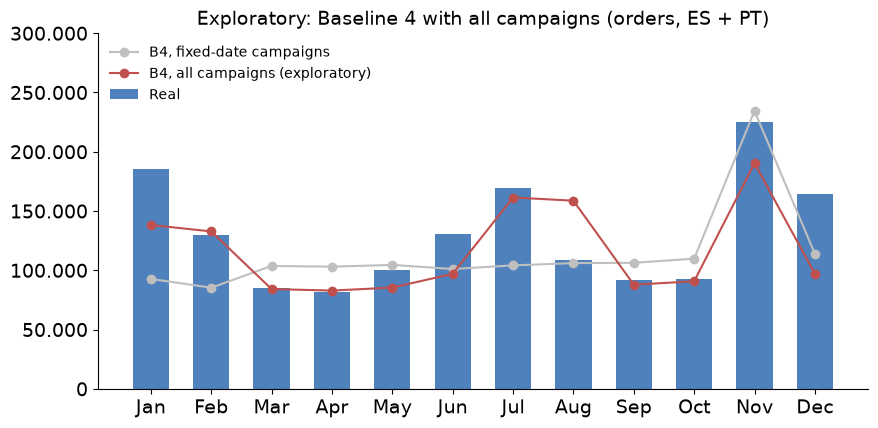

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Uses make_b4(), camp (célula 6), daily, monthly, TARGETS, run(), history(), split_of(), scorecard_common()
# (células 2 a 6), b1_daily, b3_monthly, b3_daily, TARGET, MARKETS, START, END, mk_in, mk_values, fmt()/reset() (célula 1)
# e a tabela temporária ev_b4 (célula 6). Exploratória: não grava provas (BL).
# If you restarted the kernel, run as células 1 a 6.
reset(con)
for nome in ['make_b4', 'camp', 'daily', 'monthly', 'TARGETS', 'run', 'history', 'split_of', 'scorecard_common',
             'b1_daily', 'b3_monthly', 'b3_daily', 'TARGET', 'MARKETS', 'START', 'END', 'mk_in', 'mk_values']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 a 6 e depois esta.")
try:
    con.execute("SELECT count(*) FROM ev_b4").fetchall()          # ev_b4 é uma tabela do DuckDB, criada na célula 6
except Exception:
    raise RuntimeError("A tabela ev_b4 não existe. Volta a correr a célula 6 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- campanhas incluídas (prioridade: a primeira da lista ganha se dois eventos coincidirem no mesmo dia) ----------
INCLUDE_OTHER = False
ALL_FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Free shipping', 'Get your basket ready',
            'Stock 1', 'Special prices', 'Easter and Holy Week', 'Clearance'] + (['Other'] if INCLUDE_OTHER else [])

def build_camp(fams):
    # mesma regra da célula 6: eventos válidos com mercado + linhas da Black Friday sem mercado (aplicadas aos mercados do âmbito)
    fam_in = ', '.join(f"'{f}'" for f in fams)
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE camp_days_x AS
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    rows_m AS (
      SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
        SELECT mark, family,
               unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                      CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
        FROM ev_b4 WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
    rows_g AS (
      SELECT mk.mark, g.family, g.day FROM (
        SELECT family, CAST(day_ts AS DATE) AS day FROM (
          SELECT family,
                 unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                        CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
          FROM ev_b4 WHERE valid AND mark IS NULL AND family = 'Black Friday' AND 'Black Friday' IN ({fam_in}))) g
      CROSS JOIN mk)
    SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
    """)
    c = con.sql("SELECT mark, family, day FROM camp_days_x").df()
    c['day'] = pd.to_datetime(c['day'])
    c['p'] = c['family'].map({f: i for i, f in enumerate(fams)})
    return c.sort_values(['mark', 'day', 'p']).drop_duplicates(['mark', 'day']).drop(columns='p').reset_index(drop=True)

camp_all = build_camp(ALL_FAMS)

# ---------- quantos dias ficam por família e quantos dias normais restam ----------
print('--- Dias marcados por família (depois de resolver as coincidências), por mercado ---')
cnt = camp_all.groupby(['family', 'mark']).size().unstack('mark').reindex(ALL_FAMS).fillna(0).astype(int)
total_days = (pd.Timestamp(END) - pd.Timestamp(START)).days + 1                       # 731
cnt.loc['Total marcados'] = cnt.sum()
cnt.loc['Dias normais (sem campanha)'] = total_days - cnt.loc['Total marcados']
display(cnt)

# ---------- a B4 com todas as campanhas ----------
b4x, b4x_parts = make_b4(camp_all)
NAME = 'B4 all campaigns (exploratory)'
fc_x = run(NAME, b4x, TARGET)

# ---------- factores aplicados por mês-alvo ----------
rows = []
for m in TARGETS:
    h = history(daily, m)
    for mk in MARKETS:
        p = b4x_parts(h[h['mark'] == mk], m, TARGET)
        for fam, nd in sorted(p['fam_days'].items(), key=lambda kv: ALL_FAMS.index(kv[0])):
            rows.append({'Month': m.strftime('%b %Y'), 'Market': mk, 'Campaign': fam, 'Days in the month': nd,
                         'Factor': (f"{p['factor'][fam]:.2f}".replace('.', ',') if fam in p['factor'] else '1,00'),
                         'Days measured': p['n'].get(fam, 0),
                         'Note': 'measured' if fam in p['factor'] else 'not measured: factor 1,00'})
fac = pd.DataFrame(rows)
print('\n--- Factores aplicados por mês-alvo (só com dados até ao corte) ---')
with pd.option_context('display.max_rows', None, 'display.width', 220):
    display(fac)

# ---------- erro: B1 diária, B4 de data fixa e B4 com todas as campanhas ----------
b4_fixed = run('B4 daily (fixed-date)', make_b4(camp)[0], TARGET)
fc_b1d = run('B1 daily', b1_daily, TARGET)
fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)
fc_cmp = pd.concat([fc_b1d, b4_fixed, fc_x, fc_b3], ignore_index=True)

def tidy(sc, methods):
    sc = sc.copy()
    sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
    sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
    sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
    sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
    return pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                         'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                         'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})

m3 = ['B1 daily', 'B4 daily (fixed-date)', NAME]
print(f'\n--- B1 diária, B4 de data fixa e B4 com todas as campanhas, 12 meses (alvo: {TARGET}) ---')
display(tidy(scorecard_common(fc_cmp, TARGET, m3), m3))
m4 = ['B1 daily', 'B3 monthly', 'B3 daily', 'B4 daily (fixed-date)', NAME]
print(f'--- Com a B3 (só existe de maio a dezembro de 2025; alvo: {TARGET}) ---')
display(tidy(scorecard_common(fc_cmp, TARGET, m4), m4))

# ---------- mês a mês (ES + PT) ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tot = fc_cmp.groupby(['method', 'month'])['forecast'].sum().unstack('method')
tab = pd.DataFrame(act).join(tot[['B4 daily (fixed-date)', NAME]])
mm = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index], 'Period': [split_of(m) for m in tab.index],
                   'Real': tab['Real'].map(fmt),
                   'B4 fixed-date': tab['B4 daily (fixed-date)'].map(fmt), 'Error (fixed)': (tab['B4 daily (fixed-date)'] / tab['Real'] - 1).map(pct),
                   'B4 all campaigns': tab[NAME].map(fmt), 'Error (all)': (tab[NAME] / tab['Real'] - 1).map(pct)}).reset_index(drop=True)
print(f'\n--- Mês a mês, ES + PT (alvo: {TARGET}) ---')
display(mm)

# ---------- gráfico rápido (não é gravado) ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B4 daily (fixed-date)'], color='#BFBFBF', marker='o', label='B4, fixed-date campaigns')
ax.plot(x, tab[NAME], color='#C0504D', marker='o', label='B4, all campaigns (exploratory)')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Exploratory: Baseline 4 with all campaigns ({TARGET}, ES + PT)', fontsize=14)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
ax.set_ylim(0, max(tab['Real'].max(), tab['B4 daily (fixed-date)'].max(), tab[NAME].max()) * 1.28)
ax.legend(frameon=False, loc='upper left', fontsize=10)
fig.tight_layout(); plt.show()

# Eficiência: igual à célula 6, mais um cálculo com mais dias de campanha por mês-alvo e mercado: O(d + c·28), com c ≤ d = 731;
# tempo total ~24 vezes isso; espaço O(d).

## 7. Baseline 5: day-of-week pattern (last 4 or 8 weeks) × campaign factors

**What we will do:** For each target month:
a) Take the last 4 (or 8) complete weeks (Monday to Sunday) available before the cut-off.
b) Remove all campaign days listed in the `events` table from that period.
c) Calculate the average number of orders for each day of the week using the remaining days.
d) Apply those averages to the calendar of the target month (a month with 5 Saturdays uses the Saturday average 5 times).
e) For calendar-based campaign days (Black Friday, Christmas, Mother's Day, Reyes, Valentine's Day and Easter/Holy Week), multiply the forecast by the campaign factor. This factor is measured using data available before the cut-off: actual orders divided by the average for the same days of the week 1 to 4 weeks earlier, using normal days only.

**Why:** See whether a recent day-of-week pattern, combined with calendar-based campaigns, improves on the previous baselines. Daily forecasts only.

**Decisions:** Remove all campaigns from the historical window (past campaign dates are known at the cut-off), but apply factors only to campaigns that follow a calendar. Campaigns that do not follow a fixed calendar (such as Clearance) are treated as normal days in the target month.
- Holidays are optional (`USE_HOLIDAYS`). The first run does not use them (only campaigns from the `events` table). A second run with `USE_HOLIDAYS = True` includes national holidays in Portugal and Spain (using the `holidays` package, which should be checked against an official calendar) to see what difference they make.
- If a weekday has no normal days in the window, use the average of all normal days in the window. If there are none, use the average for the full window.
- Window choice (4 or 8 weeks): select the one with the lower WAPE during training (ES + PT, 7 months), before looking at the test results.

**Reference checks:** The function matches a simple step-by-step calculation (Online ES, May, November and December 2025, for both 4- and 8-week windows). For September 2025, the last complete week ends on 2025-07-27; the 4-week window starts on 2025-06-30 and the 8-week window starts on 2025-06-02.

In [8]:
%pip install holidays

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


--- Feriados usados (pacote holidays, se ativo) e dias retirados da janela, por mercado ---


,mercado,feriados 2024-2025,dias retirados da janela (campanhas + feriados),dias com factor (data fixa + feriados)
0,Online ES,0,419,79
1,Online PT,0,422,70



--- Janelas de semanas completas (segunda a domingo) usadas em cada mês-alvo ---


,Month to forecast,Cut-off,Last complete week ends,4-week window starts,8-week window starts
0,Jan 2025,2024-11-30,2024-11-24,2024-10-28,2024-09-30
1,Feb 2025,2024-12-31,2024-12-29,2024-12-02,2024-11-04
2,Mar 2025,2025-01-31,2025-01-26,2024-12-30,2024-12-02
3,Apr 2025,2025-02-28,2025-02-23,2025-01-27,2024-12-30
4,May 2025,2025-03-31,2025-03-30,2025-03-03,2025-02-03
5,Jun 2025,2025-04-30,2025-04-27,2025-03-31,2025-03-03
6,Jul 2025,2025-05-31,2025-05-25,2025-04-28,2025-03-31
7,Aug 2025,2025-06-30,2025-06-29,2025-06-02,2025-05-05
8,Sep 2025,2025-07-31,2025-07-27,2025-06-30,2025-06-02
9,Oct 2025,2025-08-31,2025-08-31,2025-08-04,2025-07-07


Controlo à mão: para setembro de 2025 o corte é 2025-07-31 (quinta-feira); a última semana completa acaba a 2025-07-27; a janela de 4 semanas começa a 2025-06-30 e a de 8 a 2025-06-02.
Guardado: evidence_baseline/BL17.csv

--- Cobertura das janelas: quantos dos 12 meses-alvo têm dias normais suficientes ---


,semanas,mercado,meses com os 7 dias da semana medidos,meses com algum dia da semana sem dias normais (usa a média da janela),meses sem nenhum dia normal na janela (usa a janela toda)
0,4,Online ES,7,2,3
1,4,Online PT,7,2,3
2,8,Online ES,10,1,1
3,8,Online PT,10,1,1


... (11 outputs left out)

,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 monthly,Online ES,Training,3,"23,8%","-22,1%",29.988,"-1,32"
1,B1 daily,Online ES,Training,3,"24,1%","-21,4%",29.513,"-1,25"
2,B2 monthly,Online ES,Training,3,"23,6%","-10,3%",26.236,"-0,77"
3,B2 daily,Online ES,Training,3,"23,9%","-8,5%",26.030,"-0,75"
4,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,39"
5,B3 daily,Online ES,Training,3,"24,9%","15,3%",26.485,"-0,81"
6,B4 daily,Online ES,Training,3,"24,7%","-24,7%",31.681,"-1,59"
7,B5 4 weeks,Online ES,Training,3,"32,2%","-32,2%",35.003,"-2,16"
8,B5 8 weeks,Online ES,Training,3,"35,5%","-35,5%",38.545,"-2,83"
9,B1 monthly,Online ES,Test,5,"30,7%","-21,9%",44.957,"-0,34"


Guardado: evidence_baseline/BL21.csv

--- Baseline 5: mês a mês, ES + PT (alvo: orders) ---


,Month,Period,Real,B5 4 weeks,Error (4 weeks),B5 8 weeks,Error (8 weeks)
0,Jan 2025,Training,185.430,83.532,"-55,0%",83.532,"-55,0%"
1,Feb 2025,Training,129.645,121.218,"-6,5%",92.902,"-28,3%"
2,Mar 2025,Training,84.939,58.344,"-31,3%",125.918,"48,2%"
3,Apr 2025,Training,81.902,152.007,"85,6%",58.475,"-28,6%"
4,May 2025,Training,99.901,81.901,"-18,0%",82.180,"-17,7%"
5,Jun 2025,Training,130.225,88.775,"-31,8%",79.738,"-38,8%"
6,Jul 2025,Training,169.424,99.064,"-41,5%",97.066,"-42,7%"
7,Aug 2025,Test,109.025,97.555,"-10,5%",98.344,"-9,8%"
8,Sep 2025,Test,92.142,165.390,"79,5%",96.405,"4,6%"
9,Oct 2025,Test,92.795,106.471,"14,7%",133.069,"43,4%"


Guardado: evidence_baseline/BL22.csv
Guardado: evidence_baseline/BL23.png


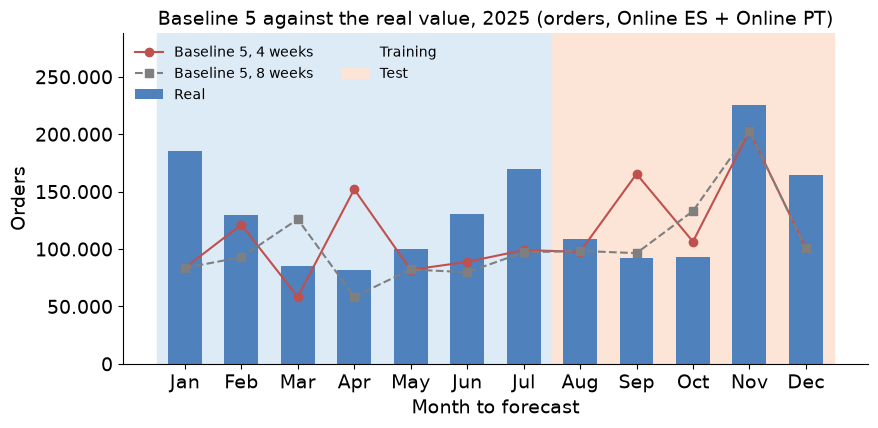

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
USE_HOLIDAYS = False       # True: usa também os feriados nacionais (pacote holidays); False: só as datas da tabela events
if USE_HOLIDAYS:
    try:
        import holidays                                # calendário de feriados nacionais; se faltar: %pip install holidays
    except ImportError:
        raise ImportError("Falta o pacote holidays. Corre %pip install holidays numa célula nova e volta a correr esta.")

# Uses daily, monthly, TARGETS, run(), scorecard(), split_of(), history(), cutoff_date() (célula 2), b1_*, b2_*, b3_*, TARGET,
# scorecard_common() (células 3 a 5), b4_daily, a tabela ev_b4 (célula 6) e files(), MARKETS, START, END, mk_in, mk_values,
# fmt()/reset()/save_table()/save_fig() (célula 1). Se reiniciaste o kernel, volta a correr as células 1 a 6.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'split_of', 'history', 'cutoff_date', 'b1_monthly', 'b1_daily',
             'b2_monthly', 'b2_daily', 'b3_monthly', 'b3_daily', 'b4_daily', 'scorecard_common', 'TARGET',
             'MARKETS', 'START', 'END', 'mk_in', 'mk_values']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 a 6 e depois esta.")
try:
    con.execute("SELECT count(*) FROM ev_b4").fetchall()          # ev_b4 é uma tabela do DuckDB, criada na célula 6
except Exception:
    raise RuntimeError("A tabela ev_b4 não existe. Volta a correr a célula 6 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- escolhas (decisão do grupo) ----------
# Remove ALL campaigns from the window (past campaigns are known at the cut-off); only calendar-based campaigns (and holidays, if enabled) receive a factor.
REMOVE_FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Free shipping', 'Get your basket ready',
               'Stock 1', 'Special prices', 'Easter and Holy Week', 'Clearance', 'Iberian blackout']
FACTOR_FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Easter and Holy Week'] + (['Holiday'] if USE_HOLIDAYS else [])   # campanhas de calendário; ordem = prioridade no mesmo dia
COUNTRY = {'Online ES': 'ES', 'Online PT': 'PT'}                                       # feriados nacionais de cada mercado
WEEKS = [4, 8]                                                                          # janelas testadas (semanas completas)
REF_LAGS, MIN_REF5 = (1, 2, 3, 4), 2        # referência de um dia especial: o mesmo dia da semana 1 a 4 semanas antes (mín. 2 dias normais)

def build_days(fams):
    # dias de campanha por mercado (mesma regra das células 6 e 6b): eventos válidos com mercado + Black Friday sem mercado
    fam_in = ', '.join(f"'{f}'" for f in fams)
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE camp_days_5 AS
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    rows_m AS (
      SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
        SELECT mark, family,
               unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                      CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
        FROM ev_b4 WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
    rows_g AS (
      SELECT mk.mark, g.family, g.day FROM (
        SELECT family, CAST(day_ts AS DATE) AS day FROM (
          SELECT family,
                 unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                        CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
          FROM ev_b4 WHERE valid AND mark IS NULL AND family = 'Black Friday' AND 'Black Friday' IN ({fam_in}))) g
      CROSS JOIN mk)
    SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
    """)
    d = con.sql("SELECT mark, family, day FROM camp_days_5").df()
    d['day'] = pd.to_datetime(d['day'])
    return d

rem_df = build_days(REMOVE_FAMS)
fac_df = build_days([f for f in FACTOR_FAMS if f != 'Holiday'])
if USE_HOLIDAYS:
    hol = {mk: {pd.Timestamp(d) for d in holidays.country_holidays(COUNTRY[mk], years=[2024, 2025])} for mk in MARKETS}
else:
    hol = {mk: set() for mk in MARKETS}                # sem feriados: só campanhas da tabela events

removed = {mk: set(rem_df.loc[rem_df['mark'] == mk, 'day']) | hol[mk] for mk in MARKETS}   # dias fora da janela
fam_day = {}                                                                                  # dia -> família com factor
for mk in MARKETS:
    dmap = {}
    for fam in reversed(FACTOR_FAMS):            # escreve primeiro a prioridade mais baixa; a mais alta sobrescreve
        if fam == 'Holiday':
            for day in hol[mk]:
                dmap[day] = 'Holiday'
        else:
            for day in fac_df.loc[(fac_df['mark'] == mk) & (fac_df['family'] == fam), 'day']:
                dmap[day] = fam
    fam_day[mk] = dmap

print('--- Feriados usados (pacote holidays, se ativo) e dias retirados da janela, por mercado ---')
display(pd.DataFrame({'mercado': MARKETS, 'feriados 2024-2025': [len(hol[m]) for m in MARKETS],
                      'dias retirados da janela (campanhas + feriados)': [len(removed[m]) for m in MARKETS],
                      'dias com factor (data fixa + feriados)': [len(fam_day[m]) for m in MARKETS]}))

# ---------- Baseline 5: perfil por dia da semana nas últimas W semanas x factores ----------
def window_bounds(m, W):
    c = cutoff_date(m)
    end = c - pd.Timedelta(days=(c.weekday() + 1) % 7)       # último domingo até ao corte: só semanas completas (segunda a domingo)
    return end - pd.Timedelta(days=7 * W - 1), end

def b5_parts(h, m, target, W, rem=None, fday=None):
    mk = h['mark'].iloc[0]
    rem = removed[mk] if rem is None else rem
    fday = fam_day[mk] if fday is None else fday
    s = h.set_index('day')[target].sort_index()
    start, end = window_bounds(m, W)
    win = s.loc[start:end]
    keep = win[[d not in rem for d in win.index]]            # janela sem campanhas nem feriados
    base_all = keep if len(keep) else win                     # reserva: se não há dias normais, usa a janela toda
    prof, fallback = {}, 0
    for k in range(7):
        v = keep[keep.index.weekday == k]
        if len(v) == 0:
            fallback += 1
        prof[k] = (v if len(v) else base_all).mean()          # valor médio de cada dia da semana (0 = segunda)
    num, den, cnt = {}, {}, {}
    for d, fam in fday.items():                               # factor: real / média do mesmo dia da semana 1 a 4 semanas antes
        if d in s.index:                                      # só dias até ao corte
            refs = [s[d - pd.Timedelta(days=7 * k)] for k in REF_LAGS
                    if (d - pd.Timedelta(days=7 * k)) in s.index and (d - pd.Timedelta(days=7 * k)) not in rem]
            if len(refs) >= MIN_REF5:
                num[fam] = num.get(fam, 0.0) + s[d]; den[fam] = den.get(fam, 0.0) + float(np.mean(refs)); cnt[fam] = cnt.get(fam, 0) + 1
    factor = {f: num[f] / den[f] for f in num}
    total, fam_days = 0.0, {}
    for d in pd.date_range(m.start_time, m.end_time.normalize()):      # soma o calendário do mês-alvo (5 sábados = 5 x sábado)
        base = prof[d.weekday()]
        fam = fday.get(d)
        if fam:
            fam_days[fam] = fam_days.get(fam, 0) + 1
        total += (base * factor.get(fam, 1.0)) if fam else base        # sem factor medido: 1,0
    return {'forecast': total, 'prof': prof, 'factor': factor, 'n': cnt, 'fam_days': fam_days, 'fallback': fallback,
            'window': (start, end), 'normal_days': len(keep)}

def make_b5(W):
    return lambda h, m, target: b5_parts(h, m, target, W)['forecast']

# ---------- janelas usadas em cada mês-alvo (BL17) ----------
rows = []
for m in TARGETS:
    c = cutoff_date(m)
    s4, e = window_bounds(m, 4); s8, _ = window_bounds(m, 8)
    rows.append({'Month to forecast': m.strftime('%b %Y'), 'Cut-off': c.strftime('%Y-%m-%d'), 'Last complete week ends': e.strftime('%Y-%m-%d'),
                 '4-week window starts': s4.strftime('%Y-%m-%d'), '8-week window starts': s8.strftime('%Y-%m-%d')})
bl17 = pd.DataFrame(rows)
print('\n--- Janelas de semanas completas (segunda a domingo) usadas em cada mês-alvo ---')
display(bl17)
print('Controlo à mão: para setembro de 2025 o corte é 2025-07-31 (quinta-feira); a última semana completa acaba a 2025-07-27; '
      'a janela de 4 semanas começa a 2025-06-30 e a de 8 a 2025-06-02.')
save_table(bl17, 'BL17', 'Baseline 5: weeks used to measure the weekday profile in each month to forecast', 'whole table')

# ---------- quantos dias normais sobram em cada janela ----------
rows = []
for W in WEEKS:
    for mk in MARKETS:
        full = part = none = 0
        for m in TARGETS:
            h = history(daily, m)
            p = b5_parts(h[h['mark'] == mk], m, TARGET, W)
            if p['normal_days'] == 0:
                none += 1
            elif p['fallback'] > 0:
                part += 1
            else:
                full += 1
        rows.append({'semanas': W, 'mercado': mk, 'meses com os 7 dias da semana medidos': full,
                     'meses com algum dia da semana sem dias normais (usa a média da janela)': part,
                     'meses sem nenhum dia normal na janela (usa a janela toda)': none})
print('\n--- Cobertura das janelas: quantos dos 12 meses-alvo têm dias normais suficientes ---')
display(pd.DataFrame(rows))

# ---------- perfil por dia da semana no período de treino (BL18) ----------
ref_end = pd.Timestamp('2025-07-31')
prof_rows = []
for mk in MARKETS:
    s = daily[(daily['mark'] == mk) & (daily['day'] <= ref_end)].set_index('day')[TARGET]
    s = s[[d not in removed[mk] for d in s.index]]                # só dias normais (sem campanhas nem feriados)
    g = s.groupby(s.index.weekday).mean()
    for k, name in enumerate(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']):
        prof_rows.append({'Market': mk, 'Weekday': name, 'Average orders': g.get(k, np.nan), 'Index (average = 100)': 100 * g.get(k, np.nan) / s.mean(),
                          'Normal days': int((s.index.weekday == k).sum())})
bl18 = pd.DataFrame(prof_rows)
bl18_show = bl18.copy()
bl18_show['Average orders'] = bl18_show['Average orders'].map(fmt)
bl18_show['Index (average = 100)'] = bl18_show['Index (average = 100)'].map(lambda v: f"{v:.0f}")
print('\n--- Perfil por dia da semana, dias normais de janeiro de 2024 a julho de 2025 (só descritivo) ---')
display(bl18_show)
save_table(bl18_show, 'BL18', 'Average orders by weekday on normal days, January 2024 to July 2025', 'whole table')

# ---------- controlo 1: B5 recalculada por outro caminho (ciclos simples) ----------
def b5_loop(h, m, target, W):
    mk = h['mark'].iloc[0]
    rem, fday = removed[mk], fam_day[mk]
    y = dict(zip(h['day'], h[target]))
    start, end = window_bounds(m, W)
    vals = {k: [] for k in range(7)}; allv, allwin = [], []
    d = start
    while d <= end:
        allwin.append(y[d])
        if d not in rem:
            vals[d.weekday()].append(y[d]); allv.append(y[d])
        d += pd.Timedelta(days=1)
    fb = allv if allv else allwin
    prof = {k: (sum(v) / len(v) if v else sum(fb) / len(fb)) for k, v in vals.items()}
    num, den = {}, {}
    for d, fam in fday.items():
        if d in y:
            refs = [y[d - pd.Timedelta(days=7 * k)] for k in REF_LAGS
                    if (d - pd.Timedelta(days=7 * k)) in y and (d - pd.Timedelta(days=7 * k)) not in rem]
            if len(refs) >= MIN_REF5:
                num[fam] = num.get(fam, 0) + y[d]; den[fam] = den.get(fam, 0) + sum(refs) / len(refs)
    total, d = 0.0, m.start_time
    while d <= m.end_time.normalize():
        fam = fday.get(d)
        total += (prof[d.weekday()] * (num[fam] / den[fam] if fam in num else 1.0)) if fam else prof[d.weekday()]
        d += pd.Timedelta(days=1)
    return total

rows = []
for W in WEEKS:
    for mth in ['2025-05', '2025-11', '2025-12']:
        mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
        a, b = b5_parts(hh, mm, TARGET, W)['forecast'], b5_loop(hh, mm, TARGET, W)
        rows.append({'semanas': W, 'mês-alvo': mth, 'mercado': 'Online ES', 'função': round(a, 2), 'ciclos simples': round(b, 2), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 1: B5 (função) contra o mesmo cálculo com ciclos simples ---')
display(pd.DataFrame(rows))

# ---------- controlo 2: sem campanhas nem feriados, a B5 é a média por dia da semana da janela x calendário do mês ----------
rows = []
for mth in ['2025-05', '2025-09']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
    start, end = window_bounds(mm, 4)
    w = hh[(hh['day'] >= start) & (hh['day'] <= end)]
    g = w.groupby(w['day'].dt.weekday)[TARGET].mean()
    ref = sum(g[d.weekday()] for d in pd.date_range(mm.start_time, mm.end_time.normalize()))
    got = b5_parts(hh, mm, TARGET, 4, rem=set(), fday={})['forecast']
    rows.append({'mês-alvo': mth, 'B5 sem calendários': round(got, 2), 'groupby (pandas)': round(ref, 2), 'bate': abs(got - ref) < 1e-6})
print('\n--- Controlo 2: sem campanhas nem feriados (Online ES, 4 semanas) ---')
display(pd.DataFrame(rows))

# ---------- factores aplicados em cada mês-alvo (BL19) ----------
rows = []
for m in TARGETS:
    h = history(daily, m)
    for mk in MARKETS:
        p = b5_parts(h[h['mark'] == mk], m, TARGET, 4)       # os factores não dependem da janela
        for fam, nd in sorted(p['fam_days'].items(), key=lambda kv: FACTOR_FAMS.index(kv[0])):
            rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Day type': fam, 'Days in the month': nd,
                         'Factor applied': (f"{p['factor'][fam]:.2f}".replace('.', ',') if fam in p['factor'] else '1,00'),
                         'Days measured in the history': p['n'].get(fam, 0),
                         'Note': 'measured' if fam in p['factor'] else 'not measured: factor 1,00'})
bl19 = pd.DataFrame(rows)
print('\n--- Factores aplicados por mês-alvo (só com dados até ao corte) ---')
with pd.option_context('display.max_rows', None, 'display.width', 220):
    display(bl19)
save_table(bl19, 'BL19', f'Baseline 5: factor applied to campaign days and holidays in each month to forecast (target: {TARGET})', 'whole table')

# ---------- previsões ----------
fc5 = pd.concat([run(f'B5 {W} weeks', make_b5(W), TARGET) for W in WEEKS], ignore_index=True)
fc_b1 = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)
fc_b2 = pd.concat([run('B2 monthly', b2_monthly, TARGET), run('B2 daily', b2_daily, TARGET)], ignore_index=True)
fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)
fc_b4 = run('B4 daily', b4_daily, TARGET)
fc_all = pd.concat([fc_b1, fc_b2, fc_b3, fc_b4, fc5], ignore_index=True)

# escolha da janela: menor WAPE no treino (ES + PT, 7 meses), regra fixada antes de ver os números
tr = scorecard(fc5, TARGET)
tr = tr[(tr['mark'] == 'ES + PT') & (tr['split'] == 'Training')].set_index('method')['WAPE']
best = tr.idxmin()
print('\n--- Escolha da janela (treino, ES + PT, 7 meses) ---')
print({k: pct(v) for k, v in tr.items()}, '-> janela escolhida:', best, '(regra: menor WAPE no treino)')

def tidy(sc, methods):
    sc = sc.copy()
    sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
    sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
    sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
    sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
    return pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                         'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                         'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})

m12 = ['B1 daily', 'B4 daily', 'B5 4 weeks', 'B5 8 weeks']
bl20 = tidy(scorecard_common(fc_all, TARGET, m12), m12)
print(f'\n--- B1 diária, B4 e B5 (4 e 8 semanas), 12 meses (alvo: {TARGET}) ---')
display(bl20)
save_table(bl20, 'BL20', f'Baselines 1 and 4 against Baseline 5 (4 and 8 weeks), 2025 (target: {TARGET})', 'whole table')

mall = ['B1 monthly', 'B1 daily', 'B2 monthly', 'B2 daily', 'B3 monthly', 'B3 daily', 'B4 daily', 'B5 4 weeks', 'B5 8 weeks']
bl21 = tidy(scorecard_common(fc_all, TARGET, mall), mall)
print(f'\n--- Todas as baselines nos meses comuns (maio a dezembro de 2025; alvo: {TARGET}) ---')
display(bl21)
save_table(bl21, 'BL21', f'Baselines 1 to 5 compared on the same months (May to December 2025; target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT) ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tot = fc_all.groupby(['method', 'month'])['forecast'].sum().unstack('method')
tab = pd.DataFrame(act).join(tot[['B5 4 weeks', 'B5 8 weeks']])
bl22 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index], 'Period': [split_of(m) for m in tab.index],
                     'Real': tab['Real'].map(fmt),
                     'B5 4 weeks': tab['B5 4 weeks'].map(fmt), 'Error (4 weeks)': (tab['B5 4 weeks'] / tab['Real'] - 1).map(pct),
                     'B5 8 weeks': tab['B5 8 weeks'].map(fmt), 'Error (8 weeks)': (tab['B5 8 weeks'] / tab['Real'] - 1).map(pct)}).reset_index(drop=True)
print(f'\n--- Baseline 5: mês a mês, ES + PT (alvo: {TARGET}) ---')
display(bl22)
save_table(bl22, 'BL22', f'Baseline 5: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico ----------
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, tab['B5 4 weeks'], color='#C0504D', marker='o', label='Baseline 5, 4 weeks')
ax.plot(x, tab['B5 8 weeks'], color='#7F7F7F', marker='s', linestyle='--', label='Baseline 5, 8 weeks')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 5 against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
ax.set_ylim(0, max(tab['Real'].max(), tab['B5 4 weeks'].max(), tab['B5 8 weeks'].max()) * 1.28)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
fig.tight_layout()
save_fig(fig, 'BL23', f'Baseline 5 against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: cada previsão filtra a tabela diária uma vez e percorre a janela (≤ 56 dias) e os dias com factor (≤ ~150) com 4 referências:
# O(d + c·4), com d = 731; tempo total ~48 vezes isso (2 janelas × 24 pares mês-alvo/mercado); espaço O(d). As tabelas e o gráfico são O(12).

### 7a. Findings (version with six calendar-based campaigns)

**Confirmed (full table):**
- All checks match.
- Campaign factors behave differently: Black Friday has a very strong positive impact, while Christmas and Mother's Day also increase orders. Easter/Holy Week and Reyes have factors below 1. Valentine's Day has no campaign days available before the cut-off, so its factor is 1.00.
- Some months still do not have enough normal days or do not include every day of the week in the reference window, especially with the 4-week window.
- The 4-week window was selected for training because its WAPE was slightly lower than the 8-week window. RMSE and R² during training favoured the 8-week window.
- B5 performs poorly during training in WAPE, RMSE and R², and does not outperform the other baselines.
- During testing, both windows improve on daily B1, especially the 8-week window, which performs better than the 4-week window in WAPE, RMSE and R². Both remain behind B3 and B4.
- Across the months available for comparison, B5 remains the weakest baseline during training and, during testing, only performs better than B1 and B2.
- B5 does not consistently improve on the other baselines. Its performance varies considerably from month to month, showing instability, particularly when it under-forecasts December.
- Test errors are concentrated mainly in September and December for the 4-week window, and in December and October for the 8-week window. This shows that the overall error hides difficulties in specific months.

## 7b. Baseline 5b: day-of-week pattern, removing only calendar-based campaigns from the window

**What we will do:** Repeat Baseline 5 (cell 7) with one change: remove only days belonging to calendar-based campaigns from the 4- or 8-week window (Black Friday, Christmas, Mother's Day, Reyes, Valentine's Day and Easter/Holy Week). Other campaigns (Clearance, Special prices, Stock 1, etc.) remain in the window and are treated as normal days. Everything else stays the same: calculate the average for each day of the week using the remaining days, apply those averages to the target month's calendar, and use a factor on calendar-based campaign days (actual orders divided by the average for the same days of the week 1 to 4 weeks earlier).

**Why:** See whether keeping more normal days in the reference window (in variant A, the 4-week window had no normal days in 3 of the 12 months) reduces the extreme errors from Baseline 5, and whether Valentine's Day can now be measured.

**Names:** B5 = variant A (cell 7, all campaigns removed); B5b = variant B (this cell).

**Rules:** Choose the 4- or 8-week window based on the lower WAPE during training (ES + PT, 7 months), before looking at the results. Holiday handling follows the `USE_HOLIDAYS` switch in cell 7.

**Reference checks:** The function matches a simple step-by-step calculation (Online ES, May, November and December 2025, for both 4- and 8-week windows). When given the same set of removed days as variant A, the function reproduces B5 from cell 7 exactly.

--- Dias retirados da janela, por variante ---


,mercado,variante A (todas as campanhas),variante B (só data fixa)
0,Online ES,419,79
1,Online PT,422,70



--- Cobertura das janelas nos 12 meses-alvo ---


,semanas,mercado,variante,meses com os 7 dias da semana medidos,meses com algum dia da semana sem dias normais,meses sem nenhum dia normal
0,4,Online ES,A,7,2,3
1,4,Online ES,B,11,1,0
2,4,Online PT,A,7,2,3
3,4,Online PT,B,11,1,0
4,8,Online ES,A,10,1,1
5,8,Online ES,B,12,0,0
6,8,Online PT,A,10,1,1
7,8,Online PT,B,12,0,0



--- Controlo 1: variante B (função) contra o mesmo cálculo com ciclos simples ---


,semanas,mês-alvo,mercado,função,ciclos simples,bate
0,4,2025-05,Online ES,63769.50,63769.50,True
1,4,2025-11,Online ES,151052.96,151052.96,True
2,4,2025-12,Online ES,79230.61,79230.61,True
3,8,2025-05,Online ES,79592.88,79592.88,True
4,8,2025-11,Online ES,158199.64,158199.64,True
5,8,2025-12,Online ES,78493.75,78493.75,True


... (5 outputs left out)

,Method,Market,Period,Months,WAPE,Bias,RMSE,R²
0,B1 monthly,Online ES,Training,3,"23,8%","-22,1%",29.988,"-1,32"
1,B1 daily,Online ES,Training,3,"24,1%","-21,4%",29.513,"-1,25"
2,B2 monthly,Online ES,Training,3,"23,6%","-10,3%",26.236,"-0,77"
3,B2 daily,Online ES,Training,3,"23,9%","-8,5%",26.030,"-0,75"
4,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,39"
...,...,...,...,...,...,...,...,...
61,B4 daily,ES + PT,Test,5,"13,8%","-1,9%",25.164,"0,76"
62,B5 4 weeks,ES + PT,Test,5,"27,0%","-1,5%",45.248,"0,23"
63,B5 8 weeks,ES + PT,Test,5,"20,7%","-7,7%",35.675,"0,52"
64,B5b 4 weeks,ES + PT,Test,5,"27,9%","4,3%",45.557,"0,22"


Guardado: evidence_baseline/BL26.csv

--- Baseline 5b: mês a mês, ES + PT (alvo: orders); as duas últimas colunas são o erro da variante A ---


,Month,Period,Real,B5b 4 weeks,"Error (5b, 4 weeks)",B5b 8 weeks,"Error (5b, 8 weeks)","Error (5, 4 weeks)","Error (5, 8 weeks)"
0,Jan 2025,Training,185.430,82.581,"-55,5%",87.787,"-52,7%","-55,0%","-55,0%"
1,Feb 2025,Training,129.645,123.044,"-5,1%",99.380,"-23,3%","-6,5%","-28,3%"
2,Mar 2025,Training,84.939,196.415,"131,2%",167.276,"96,9%","-31,3%","48,2%"
3,Apr 2025,Training,81.902,145.179,"77,3%",167.613,"104,7%","85,6%","-28,6%"
4,May 2025,Training,99.901,86.031,"-13,9%",108.671,"8,8%","-18,0%","-17,7%"
5,Jun 2025,Training,130.225,88.775,"-31,8%",83.090,"-36,2%","-31,8%","-38,8%"
6,Jul 2025,Training,169.424,99.064,"-41,5%",97.066,"-42,7%","-41,5%","-42,7%"
7,Aug 2025,Test,109.025,130.279,"19,5%",115.560,"6,0%","-10,5%","-9,8%"
8,Sep 2025,Test,92.142,166.341,"80,5%",146.124,"58,6%","79,5%","4,6%"
9,Oct 2025,Test,92.795,107.151,"15,5%",133.961,"44,4%","14,7%","43,4%"


Guardado: evidence_baseline/BL27.csv
Guardado: evidence_baseline/BL28.png


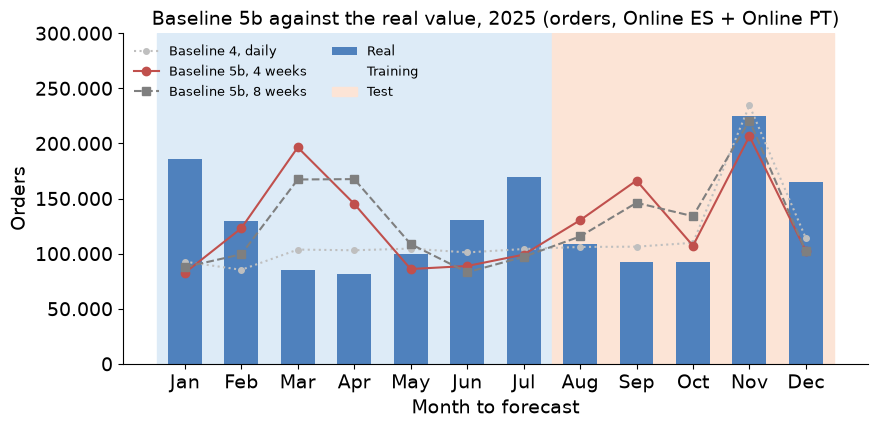

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Uses as funções e tabelas da célula 7 (b5_parts, window_bounds, make_b5, removed, fam_day, FACTOR_FAMS, REF_LAGS, MIN_REF5, WEEKS,
# USE_HOLIDAYS), daily, monthly, TARGETS, run(), scorecard(), scorecard_common(), split_of(), history() (célula 2), b1_*, b2_*, b3_*,
# TARGET (células 3 a 5), b4_daily (célula 6) e MARKETS, fmt()/reset()/save_table()/save_fig() (célula 1).
# If you restarted the kernel, run as células 1 a 7.
reset(con)
for nome in ['daily', 'monthly', 'TARGETS', 'run', 'scorecard', 'scorecard_common', 'split_of', 'history', 'b1_monthly', 'b1_daily',
             'b2_monthly', 'b2_daily', 'b3_monthly', 'b3_daily', 'b4_daily', 'TARGET', 'MARKETS',
             'b5_parts', 'window_bounds', 'make_b5', 'removed', 'fam_day', 'FACTOR_FAMS', 'REF_LAGS', 'MIN_REF5', 'WEEKS', 'USE_HOLIDAYS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 a 7 e depois esta.")

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- variante B: da janela só saem os dias com factor (campanhas de data fixa e, se ativos, feriados) ----------
# Na variante A (célula 7) saíam todas as campanhas. Na B as outras (Clearance, Special prices, Stock 1...) ficam na janela como dias normais.
removed_B = {mk: set(fam_day[mk].keys()) for mk in MARKETS}
print('--- Dias retirados da janela, por variante ---')
display(pd.DataFrame({'mercado': MARKETS,
                      'variante A (todas as campanhas)': [len(removed[m]) for m in MARKETS],
                      'variante B (só data fixa' + (' e feriados)' if USE_HOLIDAYS else ')'): [len(removed_B[m]) for m in MARKETS]}))

def make_b5b(W):
    return lambda h, m, target: b5_parts(h, m, target, W, rem=removed_B[h['mark'].iloc[0]])['forecast']

# ---------- cobertura das janelas: variante A contra variante B ----------
rows = []
for W in WEEKS:
    for mk in MARKETS:
        counts = {'A': [0, 0, 0], 'B': [0, 0, 0]}
        for m in TARGETS:
            hm = history(daily, m)
            hm = hm[hm['mark'] == mk]
            for var, rem in (('A', removed[mk]), ('B', removed_B[mk])):
                p = b5_parts(hm, m, TARGET, W, rem=rem)
                counts[var][2 if p['normal_days'] == 0 else (1 if p['fallback'] > 0 else 0)] += 1
        for var in ('A', 'B'):
            rows.append({'semanas': W, 'mercado': mk, 'variante': var, 'meses com os 7 dias da semana medidos': counts[var][0],
                         'meses com algum dia da semana sem dias normais': counts[var][1], 'meses sem nenhum dia normal': counts[var][2]})
print('\n--- Cobertura das janelas nos 12 meses-alvo ---')
display(pd.DataFrame(rows))

# ---------- controlo 1: variante B recalculada por outro caminho (ciclos simples) ----------
def b5_loop_rem(h, m, target, W, rem):
    mk = h['mark'].iloc[0]
    fday = fam_day[mk]
    y = dict(zip(h['day'], h[target]))
    start, end = window_bounds(m, W)
    vals = {k: [] for k in range(7)}; allv, allwin = [], []
    d = start
    while d <= end:
        allwin.append(y[d])
        if d not in rem:
            vals[d.weekday()].append(y[d]); allv.append(y[d])
        d += pd.Timedelta(days=1)
    fb = allv if allv else allwin
    prof = {k: (sum(v) / len(v) if v else sum(fb) / len(fb)) for k, v in vals.items()}
    num, den = {}, {}
    for d, fam in fday.items():
        if d in y:
            refs = [y[d - pd.Timedelta(days=7 * k)] for k in REF_LAGS
                    if (d - pd.Timedelta(days=7 * k)) in y and (d - pd.Timedelta(days=7 * k)) not in rem]
            if len(refs) >= MIN_REF5:
                num[fam] = num.get(fam, 0) + y[d]; den[fam] = den.get(fam, 0) + sum(refs) / len(refs)
    total, d = 0.0, m.start_time
    while d <= m.end_time.normalize():
        fam = fday.get(d)
        total += (prof[d.weekday()] * (num[fam] / den[fam] if fam in num else 1.0)) if fam else prof[d.weekday()]
        d += pd.Timedelta(days=1)
    return total

rows = []
for W in WEEKS:
    for mth in ['2025-05', '2025-11', '2025-12']:
        mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
        a, b = b5_parts(hh, mm, TARGET, W, rem=removed_B['Online ES'])['forecast'], b5_loop_rem(hh, mm, TARGET, W, removed_B['Online ES'])
        rows.append({'semanas': W, 'mês-alvo': mth, 'mercado': 'Online ES', 'função': round(a, 2), 'ciclos simples': round(b, 2), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 1: variante B (função) contra o mesmo cálculo com ciclos simples ---')
display(pd.DataFrame(rows))

# ---------- controlo 2: com o conjunto de dias da variante A, a função dá exatamente a B5 da célula 7 ----------
diffs = []
for W in WEEKS:
    for m in TARGETS:
        h = history(daily, m)
        for mk in MARKETS:
            hm = h[h['mark'] == mk]
            diffs.append(abs(b5_parts(hm, m, TARGET, W, rem=removed[mk])['forecast'] - make_b5(W)(hm, m, TARGET)))
print('\n--- Controlo 2: variante A reproduzida pela função da variante B ---')
print('Diferença máxima (encomendas):', f"{max(diffs):.9f}", '(esperado 0)')

# ---------- factores da variante B ----------
rows = []
for m in TARGETS:
    h = history(daily, m)
    for mk in MARKETS:
        p = b5_parts(h[h['mark'] == mk], m, TARGET, 4, rem=removed_B[mk])       # os factores não dependem da janela
        for fam, nd in sorted(p['fam_days'].items(), key=lambda kv: FACTOR_FAMS.index(kv[0])):
            rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Day type': fam, 'Days in the month': nd,
                         'Factor applied': (f"{p['factor'][fam]:.2f}".replace('.', ',') if fam in p['factor'] else '1,00'),
                         'Days measured in the history': p['n'].get(fam, 0),
                         'Note': 'measured' if fam in p['factor'] else 'not measured: factor 1,00'})
bl24 = pd.DataFrame(rows)
print('\n--- Factores aplicados por mês-alvo, variante B (só com dados até ao corte) ---')
with pd.option_context('display.max_rows', None, 'display.width', 220):
    display(bl24)
save_table(bl24, 'BL24', f'Baseline 5b: factor applied to fixed-date campaign days in each month to forecast (target: {TARGET})', 'whole table')

# ---------- previsões ----------
fc5a = pd.concat([run(f'B5 {W} weeks', make_b5(W), TARGET) for W in WEEKS], ignore_index=True)
fc5b = pd.concat([run(f'B5b {W} weeks', make_b5b(W), TARGET) for W in WEEKS], ignore_index=True)
fc_b1 = pd.concat([run('B1 monthly', b1_monthly, TARGET), run('B1 daily', b1_daily, TARGET)], ignore_index=True)
fc_b2 = pd.concat([run('B2 monthly', b2_monthly, TARGET), run('B2 daily', b2_daily, TARGET)], ignore_index=True)
fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)
fc_b4 = run('B4 daily', b4_daily, TARGET)
fc_all = pd.concat([fc_b1, fc_b2, fc_b3, fc_b4, fc5a, fc5b], ignore_index=True)

# escolha da janela da variante B: menor WAPE no treino (ES + PT, 7 meses), regra fixada antes de ver os números
tr = scorecard(fc5b, TARGET)
tr = tr[(tr['mark'] == 'ES + PT') & (tr['split'] == 'Training')].set_index('method')['WAPE']
print('\n--- Escolha da janela da variante B (treino, ES + PT, 7 meses) ---')
print({k: pct(v) for k, v in tr.items()}, '-> janela escolhida:', tr.idxmin(), '(regra: menor WAPE no treino)')

def tidy(sc, methods):
    sc = sc.copy()
    sc['mark'] = pd.Categorical(sc['mark'], ['Online ES', 'Online PT', 'ES + PT'], ordered=True)
    sc['split'] = pd.Categorical(sc['split'], ['Training', 'Test'], ordered=True)
    sc['method'] = pd.Categorical(sc['method'], methods, ordered=True)
    sc = sc.sort_values(['mark', 'split', 'method']).reset_index(drop=True)
    return pd.DataFrame({'Method': sc['method'].astype(str), 'Market': sc['mark'].astype(str), 'Period': sc['split'].astype(str),
                         'Months': sc['months'], 'WAPE': sc['WAPE'].map(pct), 'Bias': sc['Bias'].map(pct),
                         'RMSE': sc['RMSE'].map(fmt), 'R²': sc['R2'].map(lambda v: '-' if pd.isna(v) else f"{v:.2f}".replace('.', ','))})

m12 = ['B1 daily', 'B4 daily', 'B5 4 weeks', 'B5 8 weeks', 'B5b 4 weeks', 'B5b 8 weeks']
bl25 = tidy(scorecard_common(fc_all, TARGET, m12), m12)
print(f'\n--- B1, B4, B5 (variante A) e B5b (variante B), 12 meses (alvo: {TARGET}) ---')
display(bl25)
save_table(bl25, 'BL25', f'Baselines 1 and 4 against Baseline 5 (all campaigns removed) and 5b (only fixed-date campaigns removed), 2025 (target: {TARGET})', 'whole table')

mall = ['B1 monthly', 'B1 daily', 'B2 monthly', 'B2 daily', 'B3 monthly', 'B3 daily', 'B4 daily', 'B5 4 weeks', 'B5 8 weeks', 'B5b 4 weeks', 'B5b 8 weeks']
bl26 = tidy(scorecard_common(fc_all, TARGET, mall), mall)
print(f'\n--- Todas as baselines nos meses comuns (maio a dezembro de 2025; alvo: {TARGET}) ---')
display(bl26)
save_table(bl26, 'BL26', f'Baselines 1 to 5b compared on the same months (May to December 2025; target: {TARGET})', 'whole table')

# ---------- mês a mês (ES + PT) ----------
act = monthly[monthly['month'].isin(TARGETS)].groupby('month')[TARGET].sum().rename('Real')
tot = fc_all.groupby(['method', 'month'])['forecast'].sum().unstack('method')
tab = pd.DataFrame(act).join(tot[['B5 4 weeks', 'B5 8 weeks', 'B5b 4 weeks', 'B5b 8 weeks']])
bl27 = pd.DataFrame({'Month': [m.strftime('%b %Y') for m in tab.index], 'Period': [split_of(m) for m in tab.index],
                     'Real': tab['Real'].map(fmt),
                     'B5b 4 weeks': tab['B5b 4 weeks'].map(fmt), 'Error (5b, 4 weeks)': (tab['B5b 4 weeks'] / tab['Real'] - 1).map(pct),
                     'B5b 8 weeks': tab['B5b 8 weeks'].map(fmt), 'Error (5b, 8 weeks)': (tab['B5b 8 weeks'] / tab['Real'] - 1).map(pct),
                     'Error (5, 4 weeks)': (tab['B5 4 weeks'] / tab['Real'] - 1).map(pct),
                     'Error (5, 8 weeks)': (tab['B5 8 weeks'] / tab['Real'] - 1).map(pct)}).reset_index(drop=True)
print(f'\n--- Baseline 5b: mês a mês, ES + PT (alvo: {TARGET}); as duas últimas colunas são o erro da variante A ---')
display(bl27)
save_table(bl27, 'BL27', f'Baseline 5b: real value and forecast by month, Online ES and Online PT together (target: {TARGET})', 'whole table')

# ---------- gráfico ----------
tot4 = fc_b4.groupby('month')['forecast'].sum()
x = list(range(len(tab)))
fig, ax = plt.subplots()
ax.axvspan(-0.5, 6.5, color='#DDEBF7'); ax.axvspan(6.5, 11.5, color='#FCE4D6')
ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
ax.plot(x, [tot4[m] for m in tab.index], color='#BFBFBF', linestyle=':', marker='o', markersize=4, label='Baseline 4, daily')
ax.plot(x, tab['B5b 4 weeks'], color='#C0504D', marker='o', label='Baseline 5b, 4 weeks')
ax.plot(x, tab['B5b 8 weeks'], color='#7F7F7F', marker='s', linestyle='--', label='Baseline 5b, 8 weeks')
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b') for m in tab.index])
ax.set_title(f'Baseline 5b against the real value, 2025 ({TARGET}, Online ES + Online PT)', fontsize=14)
ax.set_xlabel('Month to forecast'); ax.set_ylabel(TARGET.replace('_', ' ').capitalize())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(int(v))))
ax.set_ylim(0, max(tab['Real'].max(), tab['B5b 4 weeks'].max(), tab['B5b 8 weeks'].max(), max(tot4)) * 1.28)
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=9)
fig.tight_layout()
save_fig(fig, 'BL28', f'Baseline 5b against the real value by month, 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: igual à célula 7, para uma segunda variante: cada previsão filtra a tabela diária uma vez e percorre a janela (≤ 56 dias)
# e os dias com factor, O(d + c·4), com d = 731; tempo total ~48 vezes isso por variante; espaço O(d). As tabelas e o gráfico são O(12).

### 7b. Findings (version with six calendar-based campaigns)

**Confirmed (full table):**
- All checks match.
- Variant B removes far fewer days from the reference window because it excludes only calendar-based campaigns. This improves coverage: with 4 weeks, every month now has at least one normal day; with 8 weeks, coverage is complete in every month.
- Valentine's Day can now be measured. This supports the explanation that its overlap with Clearance prevented it from being measured in variant A.
- Campaign factors still differ significantly: Black Friday has the largest positive impact, followed by Christmas and Mother's Day. Easter/Holy Week and Valentine's Day have factors below 1, while Reyes has an almost neutral impact.
- The 4-week window was selected for training because it had a lower WAPE than the 8-week window. As with B5, training RMSE and R² favoured the 8-week window, and during testing the 8-week window performs better on all three metrics.
- Despite better data coverage, B5b performs worse than B5 during training and does not improve test performance in WAPE, RMSE or R². Removing fewer days therefore does not lead to more accurate forecasts.
- B5b struggles to forecast the months following Clearance periods, leading to significant over-forecasting, particularly in March, April and September.
- Monthly errors continue to vary considerably, with under-forecasting in January and December and substantial over-forecasting in other months. During testing, errors are concentrated mainly in September and December, showing a strong dependence on specific periods.
- During testing, B5b only performs better than B1 and B2, and remains behind B3 and B4. Overall, neither version of Baseline 5 consistently outperforms the more effective reference methods.

## 8. Understanding baseline errors and the impact of campaigns

This section takes a closer look at the limitations identified when comparing the baseline models. It explores how forecasting errors relate to commercial campaigns, seasonal patterns and differences between markets.

The analysis focuses on four questions:

1. **Clearance:** Do the months following Clearance periods consistently show positive or negative forecasting errors?
2. **Black Friday:** Which baseline follows November most closely, and how large is the forecasting error?
3. **Christmas:** Could the under-forecasting of December by B1, B4 and B5 be linked to the Christmas period being represented by too short a window?
4. **Markets:** Do Spain and Portugal show the same error patterns, or are there meaningful differences between them?

The aim is to identify recurring error patterns and understand their possible causes, while separating the effects of campaigns known at the time of forecasting from those that can only be identified afterwards.

In [16]:

import pandas as pd
import numpy as np

# ============================================================
# 10. MONTHLY ERROR DIAGNOSTICS AND CAMPAIGN IMPACT
# ============================================================

# ---------- 1. Verificação das dependências ----------
required = [
    'daily',
    'monthly',
    'fc_all',
    'TARGET',
    'TARGETS',
    'MARKETS',
    'split_of',
    'START',
    'END',
    'save_table',
    'fmt',
    'con'
]

for name in required:
    if name not in globals():
        raise RuntimeError(
            f"Falta '{name}'. Executa primeiro as células 1 a 7."
        )

# A tabela ev_b4 é temporária no DuckDB, não uma variável Python.
try:
    reset(con)
    ev_df = con.sql("SELECT * FROM ev_b4").df()
except Exception as e:
    raise RuntimeError(
        "Não foi possível consultar a tabela ev_b4. "
        "Executa novamente a célula 6 (Baseline 4) e depois esta célula."
    ) from e

# Garantir que a análise utiliza apenas os dois mercados do projeto.
PROJECT_MARKETS = ['Online ES', 'Online PT']

if not all(m in MARKETS for m in PROJECT_MARKETS):
    raise RuntimeError(
        "Não foram encontrados os dois mercados esperados: "
        "Online ES e Online PT."
    )

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ============================================================
# 2. ERRO MENSAL DE CADA BASELINE
# ============================================================

# Valores reais por mercado e mês.
actual_market = (
    monthly[
        monthly['mark'].isin(PROJECT_MARKETS)
        & monthly['month'].isin(TARGETS)
    ]
    .groupby(['mark', 'month'], as_index=False)[TARGET]
    .sum()
    .rename(columns={TARGET: 'actual'})
)

# Valores reais agregados: Espanha + Portugal.
actual_total = (
    actual_market
    .groupby('month', as_index=False)['actual']
    .sum()
)
actual_total['mark'] = 'ES + PT'

actual_all = pd.concat(
    [actual_market, actual_total],
    ignore_index=True
)

# Previsões por baseline, mercado e mês.
forecast_market = (
    fc_all[
        fc_all['mark'].isin(PROJECT_MARKETS)
        & fc_all['month'].isin(TARGETS)
    ]
    .groupby(['method', 'mark', 'month'], as_index=False)['forecast']
    .sum()
)

# Previsões agregadas: Espanha + Portugal.
forecast_total = (
    forecast_market
    .groupby(['method', 'month'], as_index=False)['forecast']
    .sum()
)
forecast_total['mark'] = 'ES + PT'

forecast_all = pd.concat(
    [forecast_market, forecast_total],
    ignore_index=True
)

# Juntar previsão e valor real.
errors = forecast_all.merge(
    actual_all,
    on=['mark', 'month'],
    how='left',
    validate='many_to_one'
)

errors = errors.dropna(subset=['actual']).copy()

# Erros: positivo = sobrestimação; negativo = subestimação.
errors['error'] = errors['forecast'] - errors['actual']
errors['error_pct'] = errors['error'] / errors['actual']
errors['abs_error'] = errors['error'].abs()
errors['abs_error_pct'] = errors['abs_error'] / errors['actual']
errors['split'] = errors['month'].map(split_of)

errors = errors.sort_values(
    ['mark', 'method', 'month']
).reset_index(drop=True)

# Tabela BL37: erro mensal por baseline e mercado.
bl37 = errors[
    [
        'method',
        'mark',
        'month',
        'split',
        'actual',
        'forecast',
        'error',
        'error_pct',
        'abs_error',
        'abs_error_pct'
    ]
].copy()

bl37['month'] = bl37['month'].astype(str)

print('--- BL37: Erro mensal por baseline e mercado ---')
display(bl37)

save_table(
    bl37,
    'BL37',
    'Monthly forecast errors by baseline and market',
    'Training and Test; Online ES, Online PT and combined'
)

# ============================================================
# 3. IDENTIFICAÇÃO DOS DIAS DE CAMPANHA
# ============================================================

# Expandir os períodos de campanha em dias individuais.
event_rows = []

for row in ev_df.itertuples(index=False):

    if not bool(row.valid):
        continue

    start_d = pd.Timestamp(row.start_d)
    end_d = pd.Timestamp(row.end_d)

    # Limitar ao período de dados do projeto.
    start_d = max(start_d, pd.Timestamp(START))
    end_d = min(end_d, pd.Timestamp(END))

    if start_d > end_d:
        continue

    # Eventos associados a um mercado específico.
    if pd.notna(row.mark) and row.mark in PROJECT_MARKETS:
        markets_to_use = [row.mark]

    # Black Friday sem mercado: aplicar aos dois mercados,
    # seguindo a regra utilizada na Baseline 4.
    elif pd.isna(row.mark) and row.family == 'Black Friday':
        markets_to_use = PROJECT_MARKETS

    else:
        continue

    for day in pd.date_range(start_d, end_d, freq='D'):
        for market in markets_to_use:
            event_rows.append({
                'mark': market,
                'day': day,
                'family': row.family
            })

events_daily = pd.DataFrame(
    event_rows,
    columns=['mark', 'day', 'family']
)

if events_daily.empty:
    raise RuntimeError(
        "Não foram encontrados dias de campanha válidos."
    )

# Evitar duplicações do mesmo dia dentro da mesma família.
events_daily = events_daily.drop_duplicates(
    ['mark', 'day', 'family']
)

events_daily['month'] = events_daily['day'].dt.to_period('M')

# Contagem de dias por família, mercado e mês.
campaign_counts = (
    events_daily[
        events_daily['month'].isin(TARGETS)
    ]
    .groupby(['mark', 'month', 'family'])['day']
    .nunique()
    .unstack('family', fill_value=0)
)

# Contagem de dias distintos com pelo menos uma campanha.
unique_campaign_days = (
    events_daily[
        events_daily['month'].isin(TARGETS)
    ]
    .groupby(['mark', 'month'])['day']
    .nunique()
    .rename('campaign_days')
)

# Construir todas as combinações de mercado e mês-alvo.
full_index = pd.MultiIndex.from_product(
    [PROJECT_MARKETS, TARGETS],
    names=['mark', 'month']
)

bl38 = pd.DataFrame(index=full_index)

bl38 = bl38.join(campaign_counts)
bl38 = bl38.join(unique_campaign_days)

bl38 = bl38.fillna(0).reset_index()

# Dias do mês e dias sem campanha.
bl38['month_days'] = bl38['month'].map(
    lambda m: m.days_in_month
)

bl38['normal_days'] = (
    bl38['month_days'] - bl38['campaign_days']
)

# Garantir valores inteiros nas contagens.
count_cols = [
    c for c in bl38.columns
    if c not in ['mark', 'month']
]

bl38[count_cols] = bl38[count_cols].astype(int)

# Criar também a visão agregada ES + PT.
# As contagens agregadas representam dias-mercado.
bl38_total = (
    bl38
    .groupby('month', as_index=False)[count_cols]
    .sum()
)
bl38_total['mark'] = 'ES + PT'

bl38 = pd.concat(
    [bl38, bl38_total],
    ignore_index=True
)

bl38 = bl38.sort_values(
    ['mark', 'month']
).reset_index(drop=True)

bl38['month'] = bl38['month'].astype(str)

print('--- BL38: Dias de campanha por mercado e mês ---')
display(bl38)

save_table(
    bl38,
    'BL38',
    'Campaign days by family, market and month',
    '2025; Online ES, Online PT and combined'
)

# ============================================================
# 4. CRUZAMENTO DOS ERROS COM AS CAMPANHAS
# ============================================================

# Preparar a tabela de campanhas para o cruzamento.
campaign_info = bl38.copy()

# Juntar erros mensais e informação de campanhas.
bl39 = bl37.merge(
    campaign_info,
    on=['mark', 'month'],
    how='left',
    validate='many_to_one'
)

bl39 = bl39.sort_values(
    ['mark', 'month', 'method']
).reset_index(drop=True)

print('--- BL39: Erros mensais e campanhas ---')
display(
    bl39[
        (bl39['split'] == 'Test')
        & (bl39['mark'] == 'ES + PT')
    ]
)

save_table(
    bl39,
    'BL39',
    'Monthly forecast errors combined with campaign information',
    'Training and Test; Online ES, Online PT and combined'
)



--- BL37: Erro mensal por baseline e mercado ---


,method,mark,month,split,actual,forecast,error,error_pct,abs_error,abs_error_pct
0,B1 daily,ES + PT,2025-01,Training,185430,98591.289552,-86838.710448,-0.468310,86838.710448,0.468310
1,B1 daily,ES + PT,2025-02,Training,129645,93520.918033,-36124.081967,-0.278638,36124.081967,0.278638
2,B1 daily,ES + PT,2025-03,Training,84939,109935.370277,24996.370277,0.294286,24996.370277,0.294286
3,B1 daily,ES + PT,2025-04,Training,81902,108531.317647,26629.317647,0.325136,26629.317647,0.325136
4,B1 daily,ES + PT,2025-05,Training,99901,110299.223684,10398.223684,0.104085,10398.223684,0.104085
...,...,...,...,...,...,...,...,...,...,...
355,B5b 8 weeks,Online PT,2025-08,Test,29543,26629.875000,-2913.125000,-0.098606,2913.125000,0.098606
356,B5b 8 weeks,Online PT,2025-09,Test,22478,36196.750000,13718.750000,0.610319,13718.750000,0.610319
357,B5b 8 weeks,Online PT,2025-10,Test,22410,35798.375000,13388.375000,0.597429,13388.375000,0.597429
358,B5b 8 weeks,Online PT,2025-11,Test,58003,62544.566318,4541.566318,0.078299,4541.566318,0.078299


Guardado: evidence_baseline/BL37.csv
--- BL38: Dias de campanha por mercado e mês ---


,mark,month,Black Friday,Christmas,Clearance,Easter and Holy Week,Free shipping,Get your basket ready,Iberian blackout,Mothers Day,Reyes,Stock 1,Valentines,campaign_days,month_days,normal_days
0,ES + PT,2025-01,0,0,57,0,0,1,0,0,2,0,0,60,62,2
1,ES + PT,2025-02,0,0,56,0,0,0,0,0,0,0,6,56,56,0
2,ES + PT,2025-03,0,0,0,0,0,0,0,0,0,16,0,16,62,46
3,ES + PT,2025-04,0,0,0,34,0,0,2,11,0,0,0,45,60,15
4,ES + PT,2025-05,0,0,0,0,0,0,0,0,0,8,0,8,62,54
5,ES + PT,2025-06,0,0,12,0,0,2,0,0,0,0,0,14,60,46
6,ES + PT,2025-07,0,0,62,0,0,0,0,0,0,10,0,62,62,0
7,ES + PT,2025-08,0,0,62,0,0,0,0,0,0,22,0,62,62,0
8,ES + PT,2025-09,0,0,0,0,0,0,0,0,0,16,0,16,60,44
9,ES + PT,2025-10,0,0,0,0,0,0,0,0,0,16,0,16,62,46


Guardado: evidence_baseline/BL38.csv
--- BL39: Erros mensais e campanhas ---


,method,mark,month,split,actual,forecast,error,error_pct,abs_error,abs_error_pct,...,Free shipping,Get your basket ready,Iberian blackout,Mothers Day,Reyes,Stock 1,Valentines,campaign_days,month_days,normal_days
65,B1 daily,ES + PT,2025-08,Test,109025,109633.115174,608.115174,0.005578,608.115174,0.005578,...,0,0,0,0,0,22,0,62,62,0
66,B1 monthly,ES + PT,2025-08,Test,109025,107471.888889,-1553.111111,-0.014245,1553.111111,0.014245,...,0,0,0,0,0,22,0,62,62,0
67,B2 daily,ES + PT,2025-08,Test,109025,121951.944751,12926.944751,0.118569,12926.944751,0.118569,...,0,0,0,0,0,22,0,62,62,0
68,B2 monthly,ES + PT,2025-08,Test,109025,118673.666667,9648.666667,0.088500,9648.666667,0.088500,...,0,0,0,0,0,22,0,62,62,0
69,B3 daily,ES + PT,2025-08,Test,109025,111732.166341,2707.166341,0.024831,2707.166341,0.024831,...,0,0,0,0,0,22,0,62,62,0
70,B3 monthly,ES + PT,2025-08,Test,109025,115441.905933,6416.905933,0.058857,6416.905933,0.058857,...,0,0,0,0,0,22,0,62,62,0
71,B4 daily,ES + PT,2025-08,Test,109025,106048.071340,-2976.928660,-0.027305,2976.928660,0.027305,...,0,0,0,0,0,22,0,62,62,0
72,B5 4 weeks,ES + PT,2025-08,Test,109025,97555.000000,-11470.000000,-0.105205,11470.000000,0.105205,...,0,0,0,0,0,22,0,62,62,0
73,B5 8 weeks,ES + PT,2025-08,Test,109025,98343.523810,-10681.476190,-0.097973,10681.476190,0.097973,...,0,0,0,0,0,22,0,62,62,0
74,B5b 4 weeks,ES + PT,2025-08,Test,109025,130279.250000,21254.250000,0.194948,21254.250000,0.194948,...,0,0,0,0,0,22,0,62,62,0


Guardado: evidence_baseline/BL39.csv


### 8a. Findings

**Confirmed**
- Black Friday and Christmas are the months in which the baseline forecasts differ most. In November, B1 and B2 are around half the actual result. In December, every baseline except B3 is far below the actual result.
- B3 is the only baseline close to the actual result in both November and December. It is also the only baseline that uses the same month from the previous year, which is how it captures seasonal campaign patterns.
- In September and October, all baselines over-forecast, including B3. These months have few campaign days and only include Stock 1.
- Clearance does not have a consistent effect on forecasting errors. In January and February (training), B1 is far below the actual result. In August (test), despite Clearance running throughout the month, the errors are small.
- The campaign calendar is almost identical for Online ES and Online PT.
- RMSE and R² do not change these conclusions. The months with the largest absolute errors are also the months with the highest order volumes: November and December.

In [17]:
# ============================================================
# Save baseline forecasts for the statistical models notebook
# Alvo: encomendas (TARGET = 'orders').
# ============================================================
if 'fc_all' not in globals():
    raise RuntimeError("Falta 'fc_all'. Volta a correr as células 1 a 8 e depois esta.")

fc_bl = fc_all[~fc_all['method'].str.startswith('B6')][['method', 'mark', 'month', 'forecast']].copy()
fc_bl['month'] = fc_bl['month'].astype(str)          # Period -> 'AAAA-MM' (CSV não guarda o tipo Period)
fc_bl.to_csv('fc_baselines.csv', index=False)
print('Guardado: fc_baselines.csv |', len(fc_bl), 'linhas | métodos:', sorted(fc_bl['method'].unique()))

# Eficiência: filtro e escrita O(n) em n = nº de previsões (poucas centenas); espaço O(n).

Guardado: fc_baselines.csv | 240 linhas | métodos: ['B1 daily', 'B1 monthly', 'B2 daily', 'B2 monthly', 'B3 daily', 'B3 monthly', 'B4 daily', 'B5 4 weeks', 'B5 8 weeks', 'B5b 4 weeks', 'B5b 8 weeks']
